# MX Precision Lab: Error-Budgeted Accumulator Width for MX Dot-Product Cores
## IEEE SSCS Code-a-Chip Travel Grant · ISSCC 2027

**Author:** Kuan-Yu Liu | **Affiliation:** University of Toronto, Canada | **License:** Apache 2.0<br>
**Tools:** Python 3, NumPy, Matplotlib, ipywidgets, Icarus Verilog 13, Yosys 0.62, LibreLane 3.0.16 (OpenROAD, Magic 8.3.623, Netgen 1.5.316, KLayout 0.30.7), GF180MCU PDK, Graphviz, C++17

<a target="_blank" href="https://colab.research.google.com/github/12yuuuu/sscs-ose-code-a-chip.github.io/blob/submit-mx-precision-lab/ISSCC27/submitted_notebooks/mx_precision_lab/submission.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

***

## Abstract

Microscaling (MX) formats give every block of 32 elements one shared 8-bit scale. An MX dot product therefore adds block sums that sit at different exponents. The accumulator aligns them and keeps a fixed number of fractional bits. That width **W** sets both the numerical error and the silicon cost. In practice W is chosen by rule of thumb or kept wide to be safe. Neither tells a designer what a given layer actually needs.

**This notebook turns the accumulator width into a measured, error-budgeted decision.**

For a layer and two error budgets (accumulation and total), the notebook tests every input format and accumulator width on calibration data with a bit-exact integer model. It keeps the input quantization error (set by the format) apart from the accumulation error (set by W). It then joins each candidate to the hardware evidence of exactly that RTL: Icarus Verilog regressions, Yosys technology mapping, and LibreLane place and route on the open GF180MCU PDK with nine-corner static timing, DRC and LVS. A candidate is selected only if it meets both budgets and passes every physical check. The choice is frozen before the held-out test split is opened.

We report the decision and test it along six lines:

1. **Worked decision on the MXFP4 core:** on an MNIST layer with a 0.1 % accumulation and a 12 % total budget, two fractional alignment bits (F2, W18) are enough. The routed core is 58,071.8 µm², **7.15 % smaller** than the equally qualified F4 core, with +11.99 ns setup slack at 50 ns and clean DRC and LVS.
2. **Generic MX core, MXFP4 example:** the generic core implements the same alignment rule for six OCP MX encodings. For the same MXFP4 layer, W16 fails the budget and W18 maps to **1.82 % less** area than the conservative W20 (synthesis stage).
3. **Workload dependence:** across 14 layers and 6 budgets, a fixed F4 misses the calibration budget in 27 of 84 cases, while F0 or F2 would suffice in 32. For a pretrained BERT-Tiny FFN layer, the first exact configuration among the scanned candidates is F6.
4. **Verified RTL:** 16,165 regression transactions with zero mismatches on the MXFP4 core, and 1,362 on 31 generic-core configurations.
5. **A rejected alternative:** an inexact flag costs only +0.42 % routed area at F2 and never misses a lossy result, but a complete selective exact-recompute system is **40.7 % larger** than four fixed F6 cores, so the tool keeps the fixed-width core.
6. **Cycle-exact timing model:** a C++ model of that system matches the RTL in 64 cases and 424,232 events with zero cycle error, and shows that request order changes tail latency at the same flag rate.

| Metric | Value |
|:-|:-|
| PDK and flow | GF180MCU (open PDK), gf180mcu_fd_sc_mcu7t5v0, LibreLane 3.0.16 |
| Design question | accumulator width W = 16 + F of a K128, four-lane MXFP4 dot-product core |
| Selected core (MNIST fc2, 0.1 % and 12 % budgets) | W18 (F2), 58,071.8 µm² routed standard-cell area |
| Saving against the next qualified width | 7.15 % (F4: 62,543.4 µm²) |
| Timing and signoff at 50 ns | setup +11.99 ns, 9 STA corners, DRC 0, LVS 0 |
| Generic MX core, MXFP4 example, W18 vs W20 | 1.82 % less mapped area, W16 fails the budget |
| Fixed F4 across 84 workload × budget cases | misses the budget in 27, F0 or F2 is enough in 32 |
| RTL regressions | 17,527 transactions, 0 mismatches |
| Inexact flag (routed area) | +0.42 % at F2, +0.10 % at F4 |
| Selective exact recompute, N4 top | +40.7 % area vs fixed F6: rejected |
| C++ model vs RTL | 64 cases, 424,232 events, max cycle error 0 |

***

## First-Run Instructions (Google Colab)

**Step 1:** Run **Section 1** first. It gets the support package (code, RTL, data and records, 18 MB), checks its SHA-256 and unpacks it. On Colab it downloads the package from this repository, and if that fails it asks you to choose the ZIP from your computer. On your own machine it uses the package next to the notebook.

**Step 2:** Click **Runtime → Run all**. A full run takes about 1 minute on the build machine. On Colab the first run takes a few minutes longer.

**Reading only:** the saved notebook already shows every key result and figure. The GitHub preview is static, so open the notebook in Colab to use the interactive panels.

***

## Table of Contents

| Section | Content |
|:-|:-|
| 1 | Environment Setup |
| 2 | MX Dot Product and the Accumulator Width |
| 3 | Layer and Error Budget |
| 4 | Candidate Comparison |
| 5 | Where the Error Comes From |
| 6 | Circuit and Physical Evidence |
| 7 | RTL Generation and Verification |
| 8 | Physical Qualification |
| 9 | Frozen Choice and Held-out Test |
| 10 | Two Worked Decisions |
| 11 | Workload Study: 14 Layers × 6 Budgets |
| 12 | Inexact Flag and Selective Exact Recompute |
| 13 | Cycle-Exact Performance Model |
| 14 | Conclusions |
| 15 | Submission Bundle |

**Main line (Sections 3 to 9):** layer and error budgets → candidates → where the error comes from → circuit and layout → physical qualification → frozen decision. One configuration, set in the panels of Section 3, drives all of these sections. Both budgets (accumulation and total) apply at every stage. Section 10 replays two worked decisions at the default settings. Sections 11 to 13 are fixed study cases. They test the decision across workloads and against a more complex architecture.


## 1. Environment Setup

Cell 1.1 gets the support package, checks its SHA-256 and unpacks it. It then checks every file against its own SHA-256 and rebuilds the synthetic layers, which must match their recorded data exactly. The complete raw signoff reports of F2 and F4 are in the package, and Section 8 reads them again. Two kinds of evidence are not included, and the notebook says so wherever they are used:

- The raw reports of the other routed runs and the final layout views (226 MB). Only their summary numbers and SHA-256 values are kept, so the notebook cannot check their content again. This is the historical record.
- The 10,000-image test splits of the GELU+LayerNorm and K512 MNIST models. Their recorded test results are used.

Cell 1.2 prepares the runtime and the panels.


In [1]:
# 1.1 Get the support package (code, RTL, data and records), check its SHA-256 and unpack it
from pathlib import Path
import hashlib, importlib.util, os, shutil, subprocess, sys, urllib.request, zipfile
SUPPORT_ZIP, SUPPORT_SHA256 = "mx_precision_lab_support.zip", "9abc7dd1c371d331a9153508ff00defa0d1c388e9d9a4bd446b93b74055733b5"
SUPPORT_URLS = [                             # the pull-request branch, then main after the merge; the SHA-256 above pins the exact bytes
    f"https://raw.githubusercontent.com/12yuuuu/sscs-ose-code-a-chip.github.io/submit-mx-precision-lab/ISSCC27/submitted_notebooks/mx_precision_lab/{SUPPORT_ZIP}",
    f"https://raw.githubusercontent.com/sscs-ose/sscs-ose-code-a-chip.github.io/main/ISSCC27/submitted_notebooks/mx_precision_lab/{SUPPORT_ZIP}",
    f"https://raw.githubusercontent.com/12yuuuu/sscs-ose-code-a-chip.github.io/main/ISSCC27/submitted_notebooks/mx_precision_lab/{SUPPORT_ZIP}",
]
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
PROJECT_ROOT = Path.cwd().resolve() / SUPPORT_ZIP.removesuffix(".zip")
missing = [p for p in ("numpy", "matplotlib", "ipywidgets") if importlib.util.find_spec(p) is None]
if missing: subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""): h.update(block)
    return h.hexdigest()

def local_zip():                             # a copy next to the notebook comes first
    folders = [Path.cwd()] + [Path(p).resolve().parent for p in (globals().get("__vsc_ipynb_file__"), os.environ.get("JPY_SESSION_NAME")) if p]
    return next((f / SUPPORT_ZIP for f in folders if (f / SUPPORT_ZIP).is_file()), None)

def download():                              # otherwise the GitHub copy, kept only if its SHA-256 matches
    target = Path.cwd() / SUPPORT_ZIP; part = target.with_name(SUPPORT_ZIP + ".part"); errors = []
    for url in SUPPORT_URLS:
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "mx-precision-lab"}), timeout=300) as r, open(part, "wb") as f:
                shutil.copyfileobj(r, f)
            if sha256(part) == SUPPORT_SHA256: part.replace(target); return target, url
            errors.append(f"{url}: SHA-256 mismatch (a different version of the ZIP)")
        except Exception as e: errors.append(f"{url}: {e}")
        part.unlink(missing_ok=True)
    why = "\n  ".join(errors)
    hint = ("HTTP 404 means the file is not at that address: the folder is not on GitHub yet, it sits on another branch or path, or the repository is private."
            if "404" in why else "The download did not work from this runtime.")
    if IN_COLAB:                             # in Colab, pick the ZIP from your computer instead
        print(f"Could not download {SUPPORT_ZIP}:\n  {why}\n{hint}\nChoose {SUPPORT_ZIP} from your computer to continue.", flush=True)
        from google.colab import files
        for name, data in files.upload().items():
            if hashlib.sha256(data).hexdigest() == SUPPORT_SHA256:
                target.write_bytes(data)
                if Path(name).resolve() != target.resolve(): Path(name).unlink(missing_ok=True)
                return target, "the file chosen in this session"
            Path(name).unlink(missing_ok=True)
        raise RuntimeError(f"The chosen file is not {SUPPORT_ZIP} of this notebook (SHA-256 {SUPPORT_SHA256[:16]}). Run this cell again and choose the matching file.")
    raise RuntimeError(f"Could not download {SUPPORT_ZIP}:\n  {why}\n{hint}\nPut {SUPPORT_ZIP} next to this notebook and run this cell again.")

stamp = PROJECT_ROOT / ".support_sha256"
if not (stamp.exists() and stamp.read_text().strip() == SUPPORT_SHA256):
    zp, source = local_zip(), "the copy next to the notebook"
    if zp is not None and sha256(zp) != SUPPORT_SHA256:
        raise RuntimeError(f"{zp} is not the support package of this notebook (SHA-256 mismatch). Replace it with the matching {SUPPORT_ZIP}, or delete it to download the right one.")
    if zp is None: zp, source = download()
    if (PROJECT_ROOT / "SUPPORT.json").exists(): shutil.rmtree(PROJECT_ROOT)      # an older unpacked copy
    with zipfile.ZipFile(zp) as z:
        if any(n.startswith("/") or ".." in Path(n).parts or not n.startswith(PROJECT_ROOT.name + "/") for n in z.namelist()): raise ValueError("unsafe path in the support package")
        z.extractall(PROJECT_ROOT.parent)
    stamp.write_text(SUPPORT_SHA256)
    print(f"support package from {source} (SHA-256 {SUPPORT_SHA256[:16]}) unpacked into {PROJECT_ROOT}")
else:
    print(f"support package (SHA-256 {SUPPORT_SHA256[:16]}) already unpacked in {PROJECT_ROOT}")
os.chdir(PROJECT_ROOT); sys.path.insert(0, str(PROJECT_ROOT / "src"))
from mxacc import embedded
from mxacc.provenance import verify_manifest
m, info = verify_manifest(PROJECT_ROOT, prefixes=("",), exclude=()), embedded.summary(PROJECT_ROOT)   # every file of the package
print(f"support files: {m['checked']} checked against SHA256SUMS, {len(m['mismatch'])} differ, {len(m['missing'])} missing")
if m["mismatch"] or m["missing"] or not m["checked"]:   # nothing below may run on a changed project
    raise RuntimeError(f"the unpacked project differs from the support package: {(m['mismatch'] + m['missing'])[:5]}. Delete the folder {PROJECT_ROOT} and run this cell again.")
embedded.regenerate(PROJECT_ROOT)            # synthetic layers rebuilt from their generator and seed, checked against the record
print(f"raw signoff reports included for F{', F'.join(map(str, info['raw_reports_embedded']))}, re-read in Section 8")
print(f"historical record, not included: {info['attested']} raw files of the other routed runs and the final layout views ({info['attested_bytes'] / 1e6:.0f} MB). Their SHA-256 values were taken at build time and cannot be re-verified here")
print(f"test splits not included, recorded results used: {', '.join(info['recorded_test'])}")


support package from the copy next to the notebook (SHA-256 9abc7dd1c371d331) unpacked into /tmp/mx_precision_lab_run/mx_precision_lab_support
support files: 1106 checked against SHA256SUMS, 0 differ, 0 missing
regenerated 10 synthetic layers from their generator and seed; every one reproduces its recorded data hash
raw signoff reports included for F2, F4, re-read in Section 8
historical record, not included: 419 raw files of the other routed runs and the final layout views (226 MB). Their SHA-256 values were taken at build time and cannot be re-verified here
test splits not included, recorded results used: mnist_gelu_ln_fc2, mnist_relu_fc2_k512


In [2]:
# 1.2 Runtime: Colab widgets and Icarus Verilog, the hardware tools present, and the panels
if IN_COLAB:
    from google.colab import output; output.enable_custom_widget_manager()      # ipywidgets 8 panels in Colab
    if not shutil.which("iverilog"):                                             # Icarus Verilog for Sections 7 and 13
        subprocess.run("apt-get update -qq && apt-get install -y -qq iverilog", shell=True, capture_output=True)
import numpy as np, matplotlib, ipywidgets, mxlab
from mxlab.ui import Lab, tool_status
from mxlab import figures
figures.save_to(PROJECT_ROOT / "results/figures")                              # every figure is also kept for Section 15
print(f"Python {sys.version.split()[0]}, NumPy {np.__version__}, Matplotlib {matplotlib.__version__}, ipywidgets {ipywidgets.__version__}, Colab: {IN_COLAB}")
print("hardware tools:", ", ".join(f"{k} {'yes' if v else 'no'}" for k, v in tool_status().items()))
lab = Lab(PROJECT_ROOT)
print(f"{len(lab.s.catalogue)} layers; backends: " + ", ".join(b.short for b in mxlab.backends.BACKENDS.values()))


Python 3.13.16, NumPy 2.5.3, Matplotlib 3.11.2, ipywidgets 8.1.5, Colab: False
hardware tools: iverilog yes, vvp yes, yosys yes, dot yes, librelane no
15 layers; backends: MXFP4 core, Generic MX core


In [3]:
# 1.3 Settings the panels do not hold (layer, budget, clock and rate come from the panels of Section 3)
MAX_P99_CYCLES, OOC_POLICY = 200, "reject"   # limits of the recompute system (Section 12)
RUN_RTL = True                               # run the Icarus regressions when iverilog is present
from mxacc import studies, notebook_plots as plots
from mxlab.figures import show
print(f"recompute system limits: P99 at most {MAX_P99_CYCLES} cycles, out-of-contract policy {OOC_POLICY}; live RTL runs: {RUN_RTL}")


recompute system limits: P99 at most 200 cycles, out-of-contract policy reject; live RTL runs: True


## 2. MX Dot Product and the Accumulator Width

An MX dot product of length K has B = K/32 blocks. Each block g has an exact integer sum $S_g$ (14 bits for MXFP4) and a shared exponent $E_g$. The accumulator aligns every block to the largest exponent $E_{max}$ and keeps F fractional bits, rounding once per block (round to nearest, ties to even):

$$T_g = \mathrm{RNE}\left(S_g \cdot 2^{\,E_g - E_{max} + F}\right), \qquad \hat y = 2^{\,E_{max} - F} \sum_g T_g, \qquad W = 14 + \log_2 B + F$$

For K = 128 (B = 4) the width is W = 16 + F. Two errors are kept apart throughout the notebook:

| Error | Compared against | Controlled by |
|:-|:-|:-|
| Input quantization | the original FP32 layer | the format (W cannot change it) |
| Accumulation | exact accumulation of the same MX inputs | W (equivalently F) |

$F \ge \max_g (E_{max} - E_g)$ is sufficient for zero accumulation error, and the absolute error is at most $(B/2) \cdot 2^{\,E_{max} - F}$.

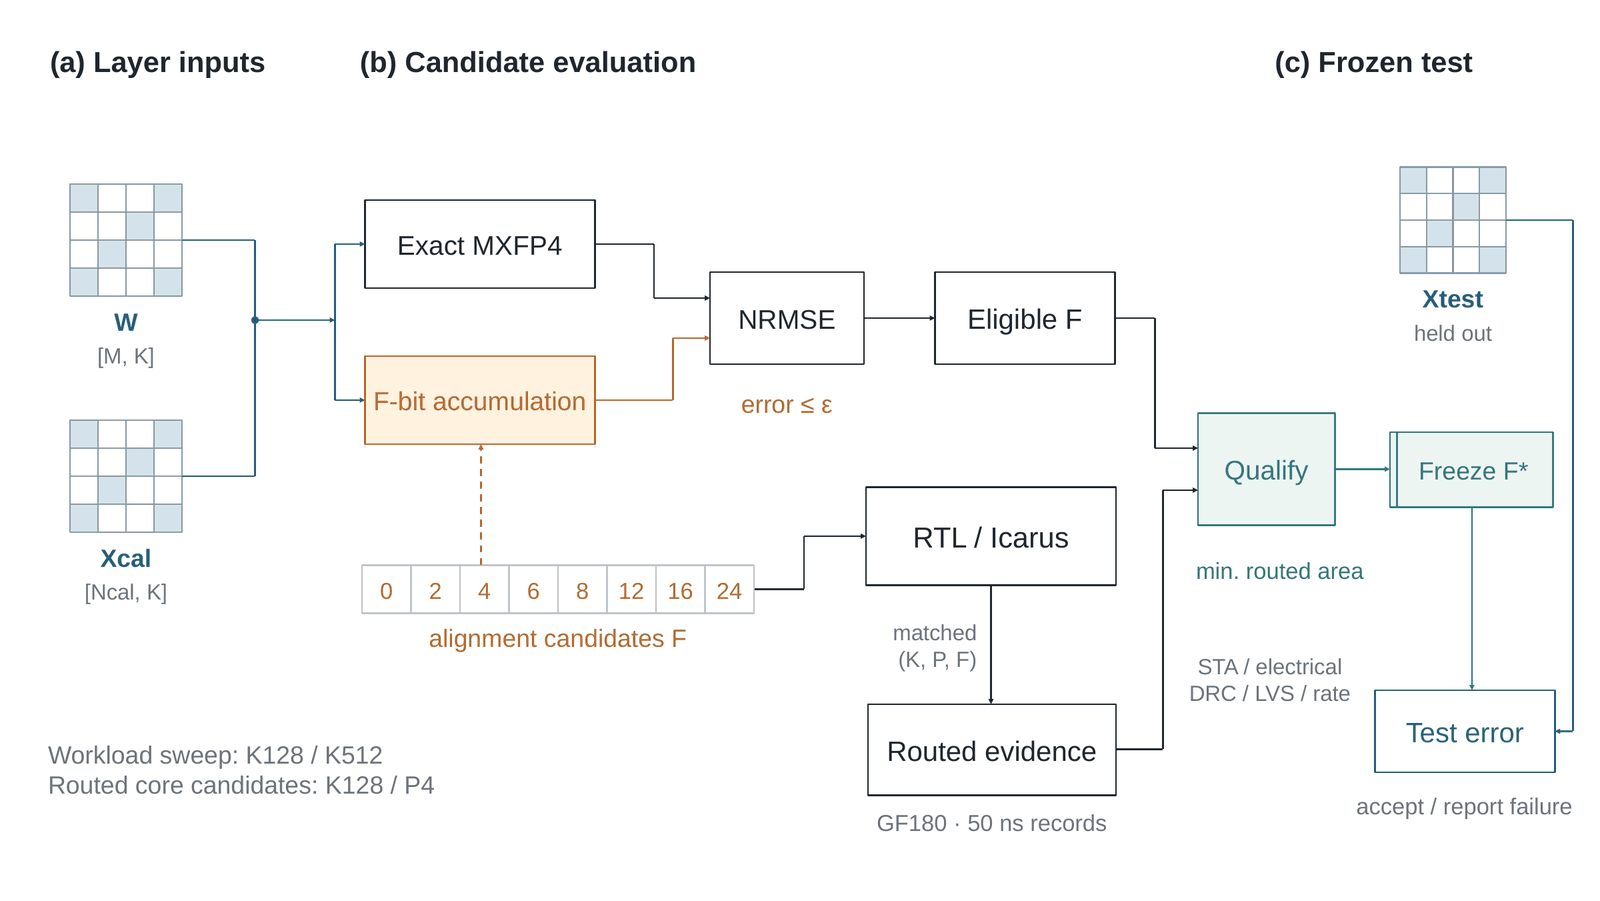

*Figure 1. Selection flow. Calibration compares each candidate with the exact dot product of the same MX inputs. Matching RTL and routed records decide physical eligibility. The smallest eligible candidate is frozen before the test split is opened.*

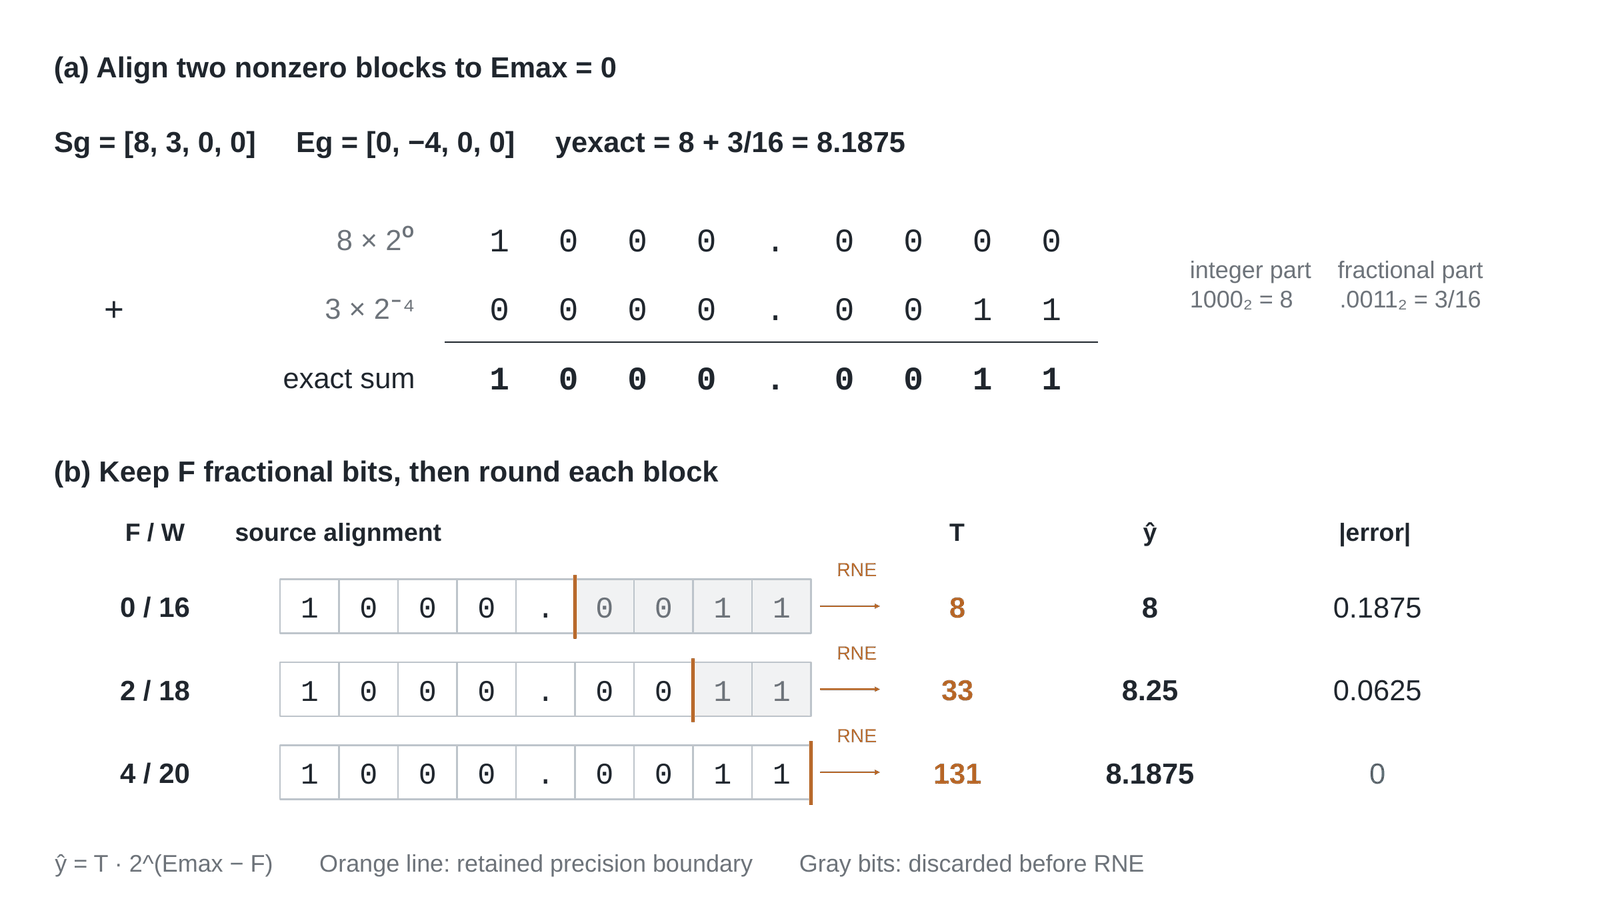

*Figure 2. Alignment at F0, F2 and F4 for two non-zero blocks, 8 and 3 · 2⁻⁴ (exact sum 8.1875). Grey cells are discarded bits. F2 gives 8.25. F4 keeps every bit and is exact. Cell 2.1 computes the same values.*


In [4]:
# 2.1 The example of Figure 2: block sums 8 (E = 0) and 3 (E = -4), with result, error and bound for F0 to F12
example = studies.worked_example(block2_sum=3, block2_exp=-4)


exact sum 8.1875, block exponent spread 4 bits

  F   W     result   abs error  bound (B/2)·2^(Emax-F)
  0  16          8      0.1875                       2
  2  18       8.25      0.0625                     0.5
  4  20     8.1875           0                   0.125   exact: F ≥ spread
  8  24     8.1875           0               0.0078125   exact: F ≥ spread
 12  28     8.1875           0             0.000488281   exact: F ≥ spread


## 3. Layer and Error Budget

Choose the layer, the backend and the two budgets. This one configuration drives every panel below and the studies of Sections 7 to 12. A change marks earlier results as stale until they run again. The default is the full MNIST fc2 layer (512 calibration rows, the official 10,000-image test split) with a 12 % total and a 0.1 % accumulation budget, at 50 ns and at least 100,000 dot products per second.

There are two backends. The **MXFP4 core** has routed GF180MCU records. The **generic MX core** supports six MX encodings and has synthesis records only. To bring your own layer, see Reproducibility in Section 14.


In [5]:
# 3.1 Default demo (one click restores it) and the controls every later panel and study shares
lab.quick_start()
lab.layer_panel()


[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]

[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]

## 4. Candidate Comparison

**Compare candidates** evaluates every format × width of the backend on the calibration split and joins each candidate to the implementation record of the same RTL. In the cost chart: green is recommended, blue is qualified and routed, red cross-hatched is routed but fails a physical check, grey hatched is synthesis only, and a hollow bar fails the error budget. A candidate without a record is not drawn.


[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]

Format,Narrowest eligible W,total NRMSE (cal),accumulation NRMSE (cal),Area of that W · source,Smallest qualified routed
MXFP4 / E2M1,W18 (F = 2),10.66 %,0.002223 %,"58,072 µm² · post-route","W18 · 58,072 µm²"


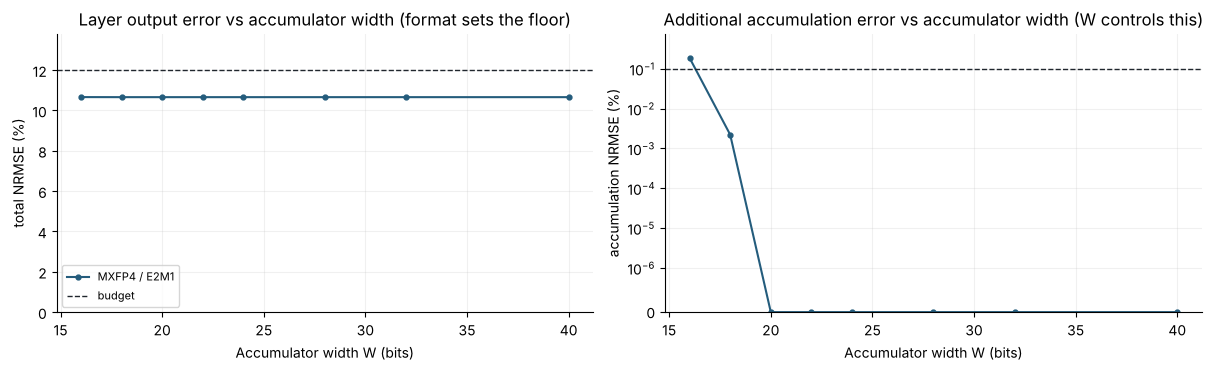

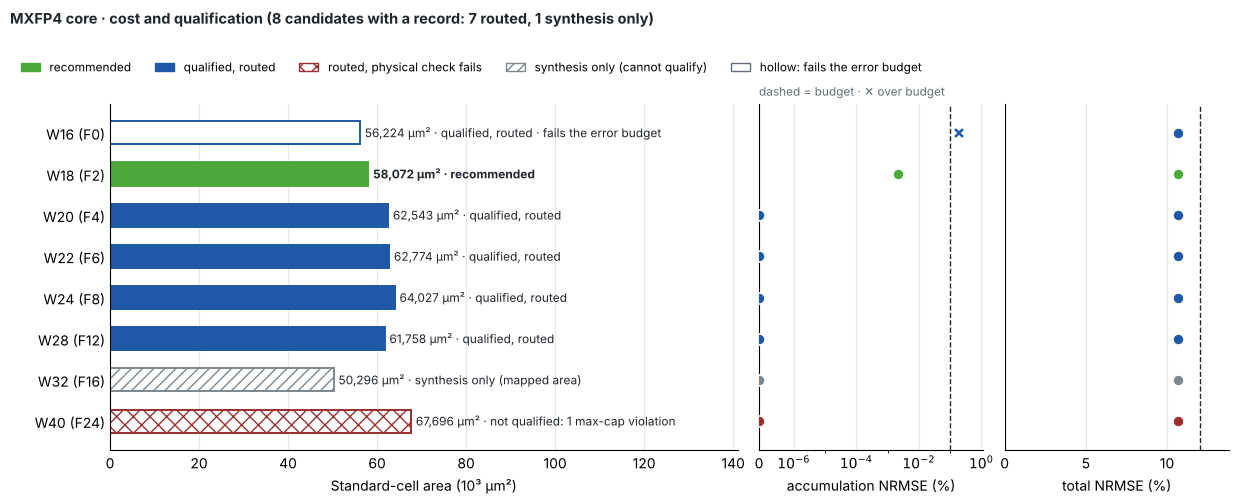

In [6]:
# 4.1 Every candidate: eligibility, error against width, and cost with qualification
lab.compare_panel()


## 5. Where the Error Comes From

Cell 5.1 separates the three errors of one design point and lists its schedule, area and slack. Cell 5.2 shows the alignment, the discarded bits and the rounding of one real dot product, block by block.


[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]

Item,Value,Meaning
Backend · format · W,MXFP4 core · MXFP4 / E2M1 · W18,bit-exact integer model of the MXFP4 core RTL
Exact block sum,14 bits,every 32-element block is summed exactly before any rounding
Derived F (fractional alignment bits),2,F = W − block-sum bits − log2(blocks); the MXFP4 core calls its candidates by F
Blocks · lanes,4 × 32 elements · P = 4,K = 128
Schedule,"II = 40 cycles, latency 39 cycles","no-stall interface; cycles, not time"
Inexact dot products,0.03662 %,fraction of calibration dot products that discarded a non-zero bit: what the OPTIONAL flag variant would report. The baseline core and its records have no flag
Area,"58,072 µm² (post-route)","from the record that matches this backend, format, K, P, W and RTL hash"
Post-route setup / hold slack,+11.993 ns / +0.206 ns,worst corner at the 50 ns target; a target is not an achieved fmax
Qualification,qualified,every physical check passed


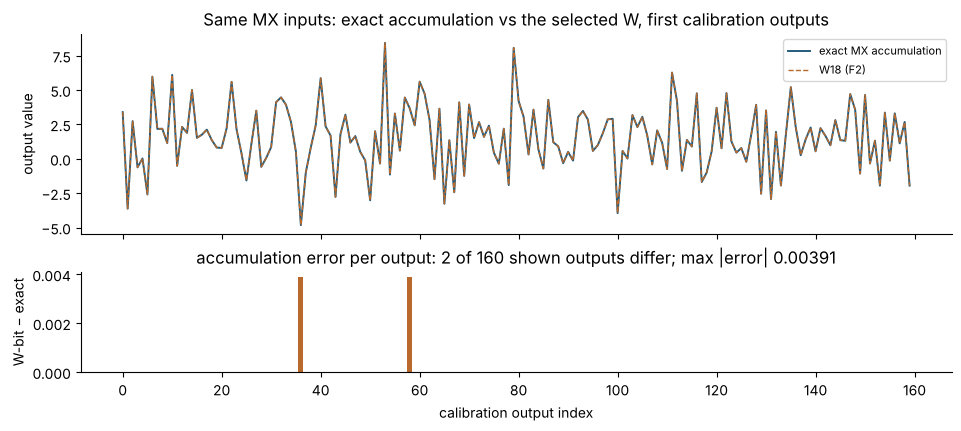

In [7]:
# 5.1 One design point: quantization, accumulation and total error, contract and evidence
lab.inspect_panel()


[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]

block,exact block sum Sg,Eg,shift,retained (floor),discarded bits,after RNE,status
0,-281,-7,left 0,-281,none,-281,exact
1,-98,-7,left 0,-98,none,-98,exact
2,-4,-5,left 2,-16,none,-16,exact
3,-445,-8,right 1,-223,1,-222,non-zero bits lost


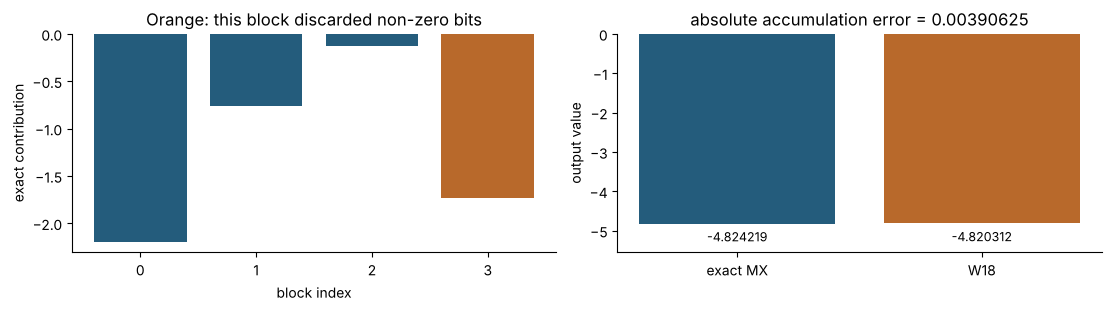

In [8]:
# 5.2 The bits of one real calibration dot product (the first one that discards a non-zero bit)
lab.bits_panel()


## 6. Circuit and Physical Evidence

The two concept views below follow the RTL dataflow. Their vector originals and drawing script are in the support package. The panel shows the actual netlist of the current design point (RTL logic cones from Yosys, and GF180 standard cells after mapping), the routed layout drawn from its polygons, and the PPA table of the same RTL. A quantity without a record is shown as *Not measured*.

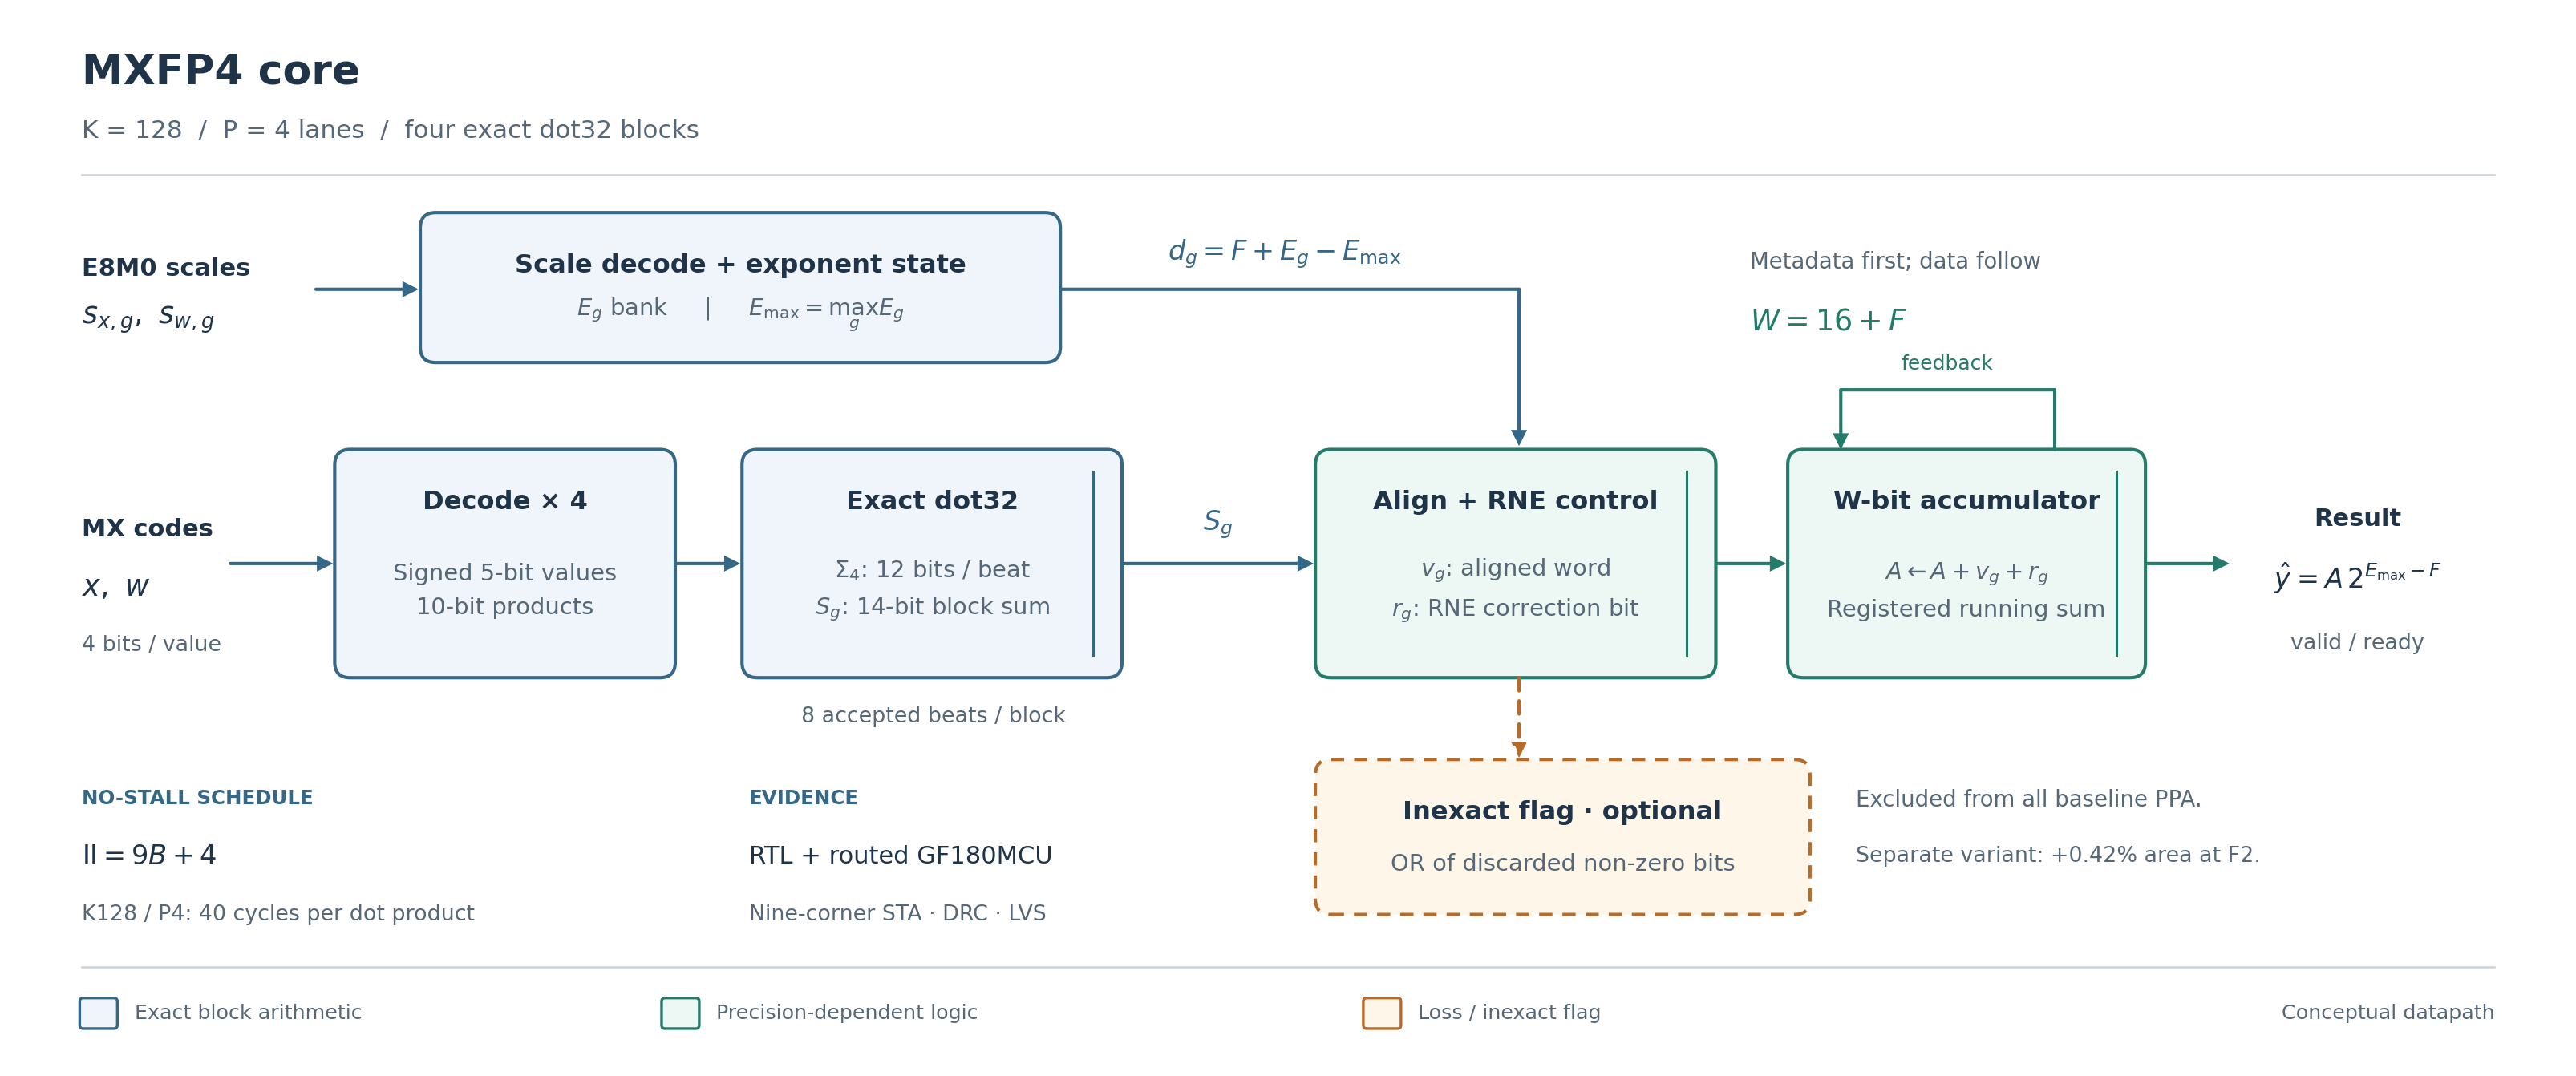

*Figure 3. MXFP4 core, K128 and four lanes. Blue logic computes exact block sums. Green logic aligns them and accumulates at width W. Register marks and the accumulator feedback follow the RTL. The dashed loss flag belongs to a separately measured variant and is excluded from baseline PPA.*

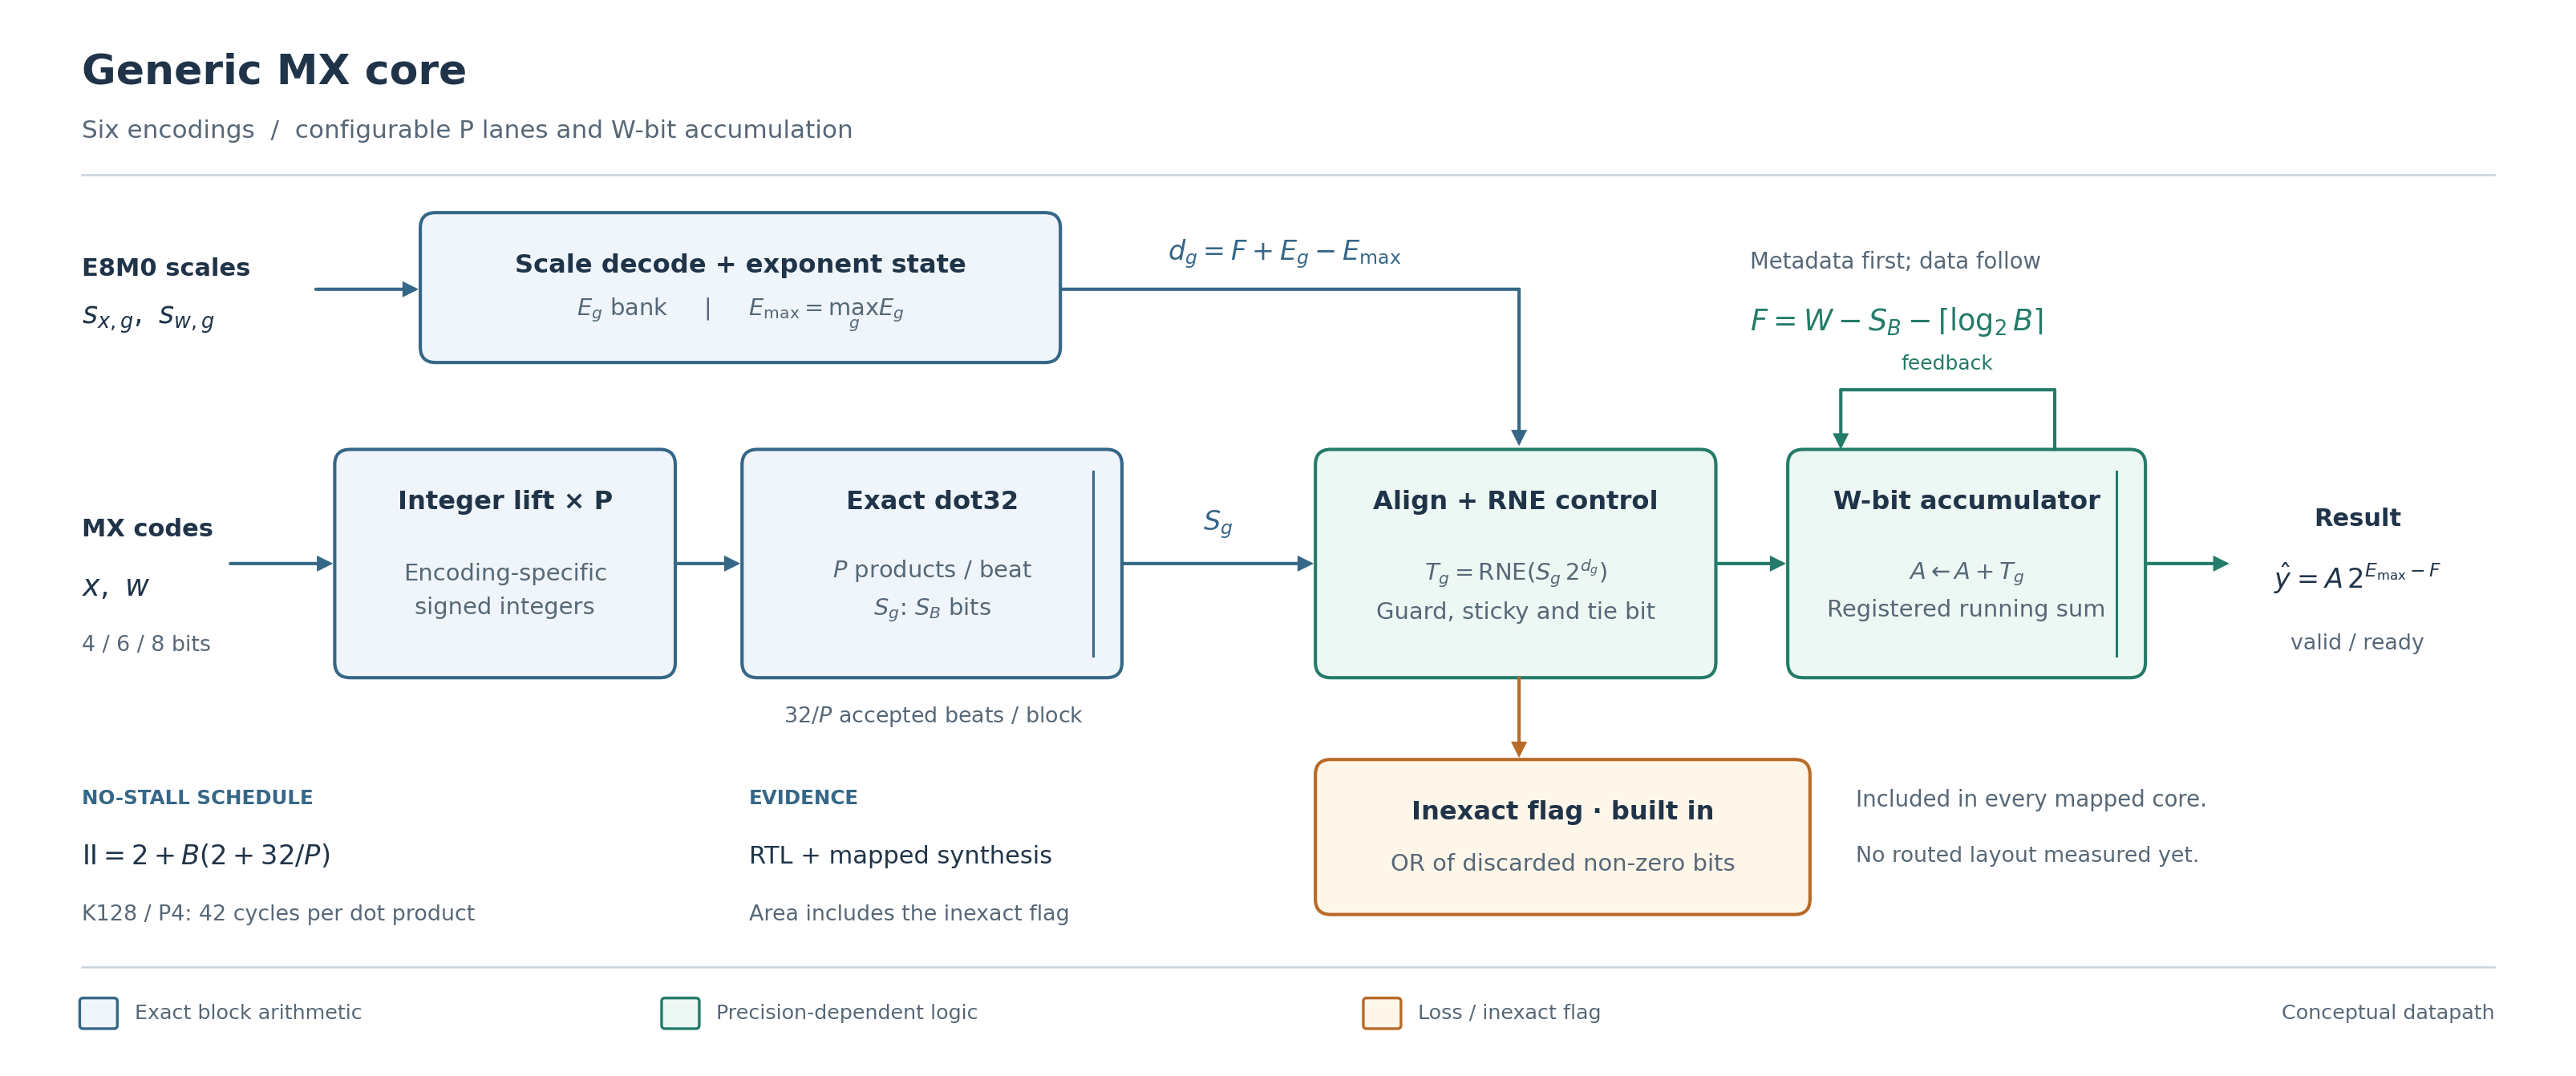

*Figure 4. Generic MX core, in the same visual notation. The encoding sets the integer block-sum width $S_B$, and W sets the alignment precision. Each block uses a separate serial merge phase. The built-in inexact flag is included in mapped area. This backend has no routed-layout evidence.*


[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]


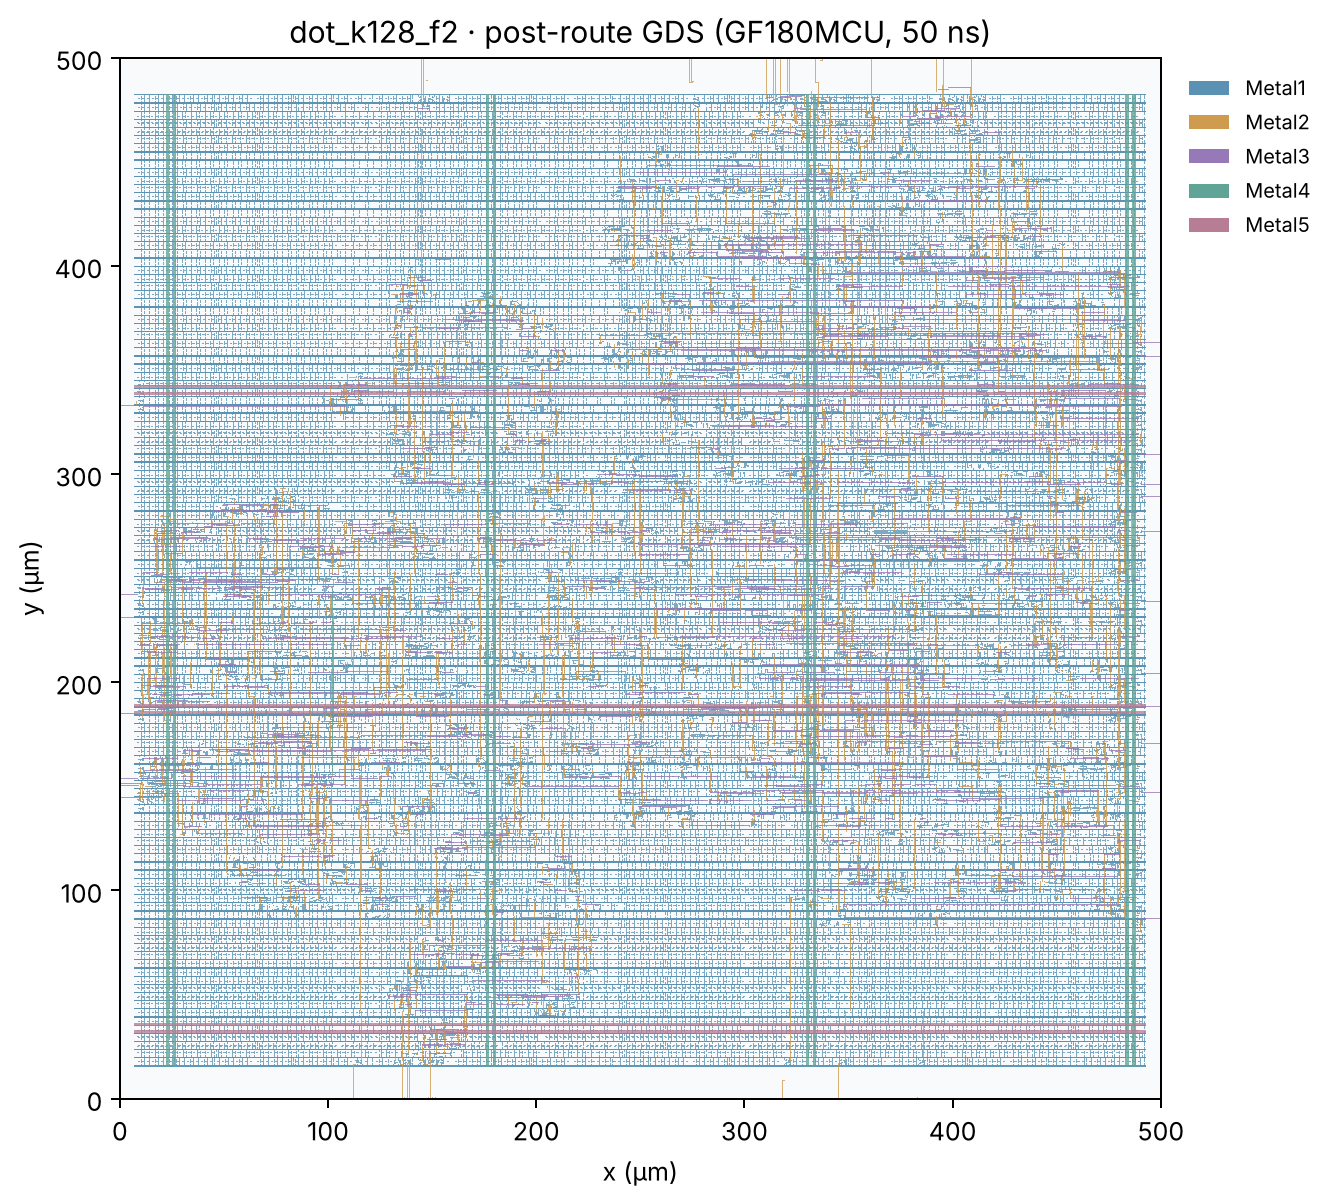

Metric,Value,Source / condition
Area · technology-mapped (synthesis),"43,146.7 µm²",Yosys + ABC technology mapping with the GF180 1x TT 5 V Liberty (exploratory; not routed)
Area · routed standard cells,"58,071.8 µm²","LibreLane 3.0.16 place-and-route on GF180MCU, nine-corner post-route STA, Magic DRC, Netgen LVS, KLayout XOR; die 250,000 µm²"
Timing · target clock,50 ns (20.0 MHz),"a target, not an achieved fmax"
Timing · post-route setup slack (worst corner),11.993 ns,9 STA corners
Timing · post-route hold slack (worst corner),0.206 ns,checked separately from setup
Schedule · initiation interval,40 cycles per dot product,"no-stall interface, one transaction at a time"
Schedule · latency,39 cycles (start accept → result valid),no input/output stalls
Rate at the target clock,"500,000 dot products/s",f_clk / II; only meaningful if timing closes
Signoff · DRC / LVS,0 / 0 errors,Magic DRC and Netgen LVS
Signoff · electrical (max slew / max cap violations),0 / 0,post-route STA checks


In [9]:
# 6.1 Circuit view, layout view and PPA table of the current design point
lab.hardware_panel()


## 7. RTL Generation and Verification

Sections 7 to 12 analyse the configuration the panels hold: the layer, both budgets, the clock and the rate. Each section prints it first. To analyse another configuration, change the panels and run these sections again. The numeric stage picks the smallest F that meets both budgets on calibration data, exactly as the panel of Section 4 does. The generator then writes the K128 core for each candidate F, and Icarus Verilog checks every result against the integer model.

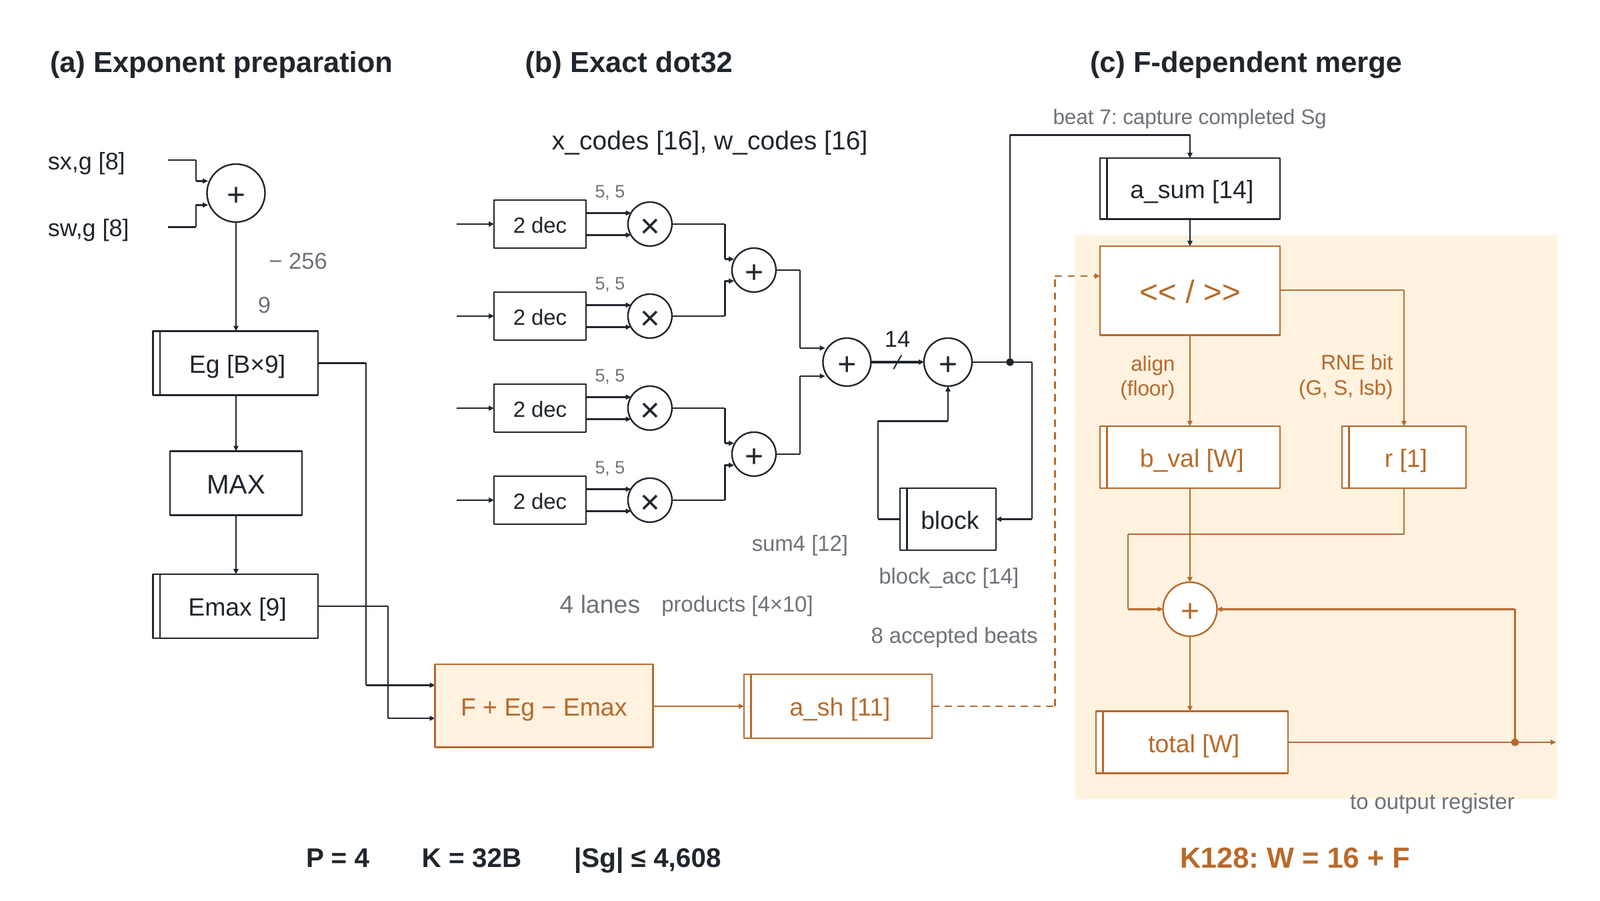

*Figure 5. Datapath of one generated core. Each lane decodes two 4-bit operands to signed 5-bit integers, and the 4-way sum is accumulated exactly into the 14-bit block sum. Only the alignment and the cross-block accumulation (orange) depend on F. Widths are RTL declarations.*


In [10]:
# 7.1 The panel configuration and its numeric stage: the smallest F that meets both budgets on calibration
cfg = studies.panel_config(lab, section=7)
numeric = studies.numeric_record(PROJECT_ROOT, cfg)


Configuration for Section 7 (shared with the panels of Sections 3 to 9): MNIST fc2, ReLU model (512 cal / 10,000 test, K128) [mnist_relu_fc2], K128, MXFP4 core, accumulation budget 0.1 %, total budget 12 %, clock 50 ns, at least 100,000 dot products/s
mnist_relu_fc2: K128, P4, accumulation budget 0.001, total budget 0.12, data 54464539fa8d…
    F  accumulation NRMSE  total NRMSE  meets both
    0             0.00189       0.1066  no
    2           2.223e-05       0.1066  yes
    4                   0       0.1066  yes
    6                   0       0.1066  yes
    8                   0       0.1066  yes
   12                   0       0.1066  yes
   16                   0       0.1066  yes
   24                   0       0.1066  yes
  numeric minimum F2 (W18); feasible F [2, 4, 6, 8, 12, 16, 24]
  bounded mode (E_max ≤ 0, |error| ≤ 0.01): F8 without data; outside the contract (cal/test): 0/0
  infeasible demo: no candidate (no candidate satisfies this conservative bound; not a proof 

In [11]:
# 7.2 Generate the candidate RTL and run a short Icarus regression of each (the saved full regression is listed first)
rtl = studies.rtl_check(PROJECT_ROOT, numeric, run=RUN_RTL, in_colab=IN_COLAB)


generated dot_k128_f0    W16
generated dot_k128_f2    W18
generated dot_k128_f4    W20
generated dot_k128_f24   W40

saved regression: 15 configurations, 16,165 transactions, 0 mismatches; no-stall II (K: cycles) {32: 13, 128: 40, 512: 148}
this run: K128 F0  425 transactions, 0 mismatches, II 40, pass
this run: K128 F2  425 transactions, 0 mismatches, II 40, pass
this run: K128 F4  425 transactions, 0 mismatches, II 40, pass
this run: K128 F24 425 transactions, 0 mismatches, II 40, pass


## 8. Physical Qualification

Each candidate F is matched to its routed record by K, lanes, F and RTL hash (LibreLane, 500 × 500 µm die, nine STA corners, Magic DRC, Netgen LVS). A candidate qualifies only if it meets both error budgets on calibration and passes every physical check: non-negative setup and hold slack at every corner, no slew or capacitance violation, zero DRC and LVS errors, and the required rate. The smallest qualified area wins. The frozen choice is then tested once on the independent split against both budgets.

The raw signoff reports of F2 and F4 are included, and cell 8.2 reads them again. The other routed records are the historical record: summary numbers and SHA-256 values, without the raw reports. If an evidence check fails, for example because a report changed, the run stops with an error instead of printing a warning.


In [12]:
# 8.1 Qualify every candidate for the panel configuration and select the smallest qualified routed core
cfg = studies.panel_config(lab, section=8)
hardware = studies.physical_selection(PROJECT_ROOT, numeric, cfg)


Configuration for Section 8 (shared with the panels of Sections 3 to 9): MNIST fc2, ReLU model (512 cal / 10,000 test, K128) [mnist_relu_fc2], K128, MXFP4 core, accumulation budget 0.1 %, total budget 12 %, clock 50 ns, at least 100,000 dot products/s
mnist_relu_fc2, K128/P4, accumulation budget 0.001, total budget 0.12, 50 ns, ≥ 100,000 dot products/s
  F stage            area µm²   setup   hold slew/cap DRC/LVS  II   evidence  qualified
  0 post_route        56223.5    9.94   0.21      0/0     0/0  40 historical    no: calibration accumulation error exceeds budget
  2 post_route        58071.8   11.99   0.21      0/0     0/0  40        raw  yes
  4 post_route        62543.4   11.99   0.16      0/0     0/0  40        raw  yes
  6 post_route        62773.9   12.49   0.18      0/0     0/0  40 historical  yes
  8 post_route        64027.4   11.91   0.17      0/0     0/0  40 historical  yes
 12 post_route        61757.6   12.07   0.13      0/0     0/0  40 historical  yes
 16 post_synthesi

In [13]:
# 8.2 Re-read the raw STA, DRC, LVS and XOR reports of F2 and F4 and compare them with the records used above
signoff = studies.signoff_recheck(PROJECT_ROOT)


Fixed study case (independent of the panels): the raw signoff reports of F2, F4 (the selected core of the default configuration and its alternative)
quantity                           read from                        F2 raw     record     F4 raw     record
setup WS, min of 9 corners (ns)    STA worst-slack reports         11.9926    11.9926    11.9911    11.9911
hold WS, min of 9 corners (ns)     STA worst-slack reports          0.2055     0.2055     0.1626     0.1626
unconstrained endpoints            STA check reports                     0          0          0          0
max slew violations                STA check reports                     0          0          0          0
max cap violations                 STA check reports                     0          0          0          0
Magic DRC errors                   Magic DRC report                      0          0          0          0
Netgen LVS errors                  Netgen LVS report                     0          0          

In [14]:
# 8.3 The same core, clock, flow and split under other selection policies ("saved" = routed area saved against fixed F4)
policies = studies.policy_comparison(PROJECT_ROOT, numeric, hardware)


policy                                          F test acc. test total budgets  routed µm²   saved  qualified
fixed F4 (no selection)                        F4         0      0.107    pass    62,543.4  +0.00%  yes
fixed F8 (higher precision)                    F8         0      0.107    pass    64,027.4  -2.37%  yes
fixed F12 (higher precision)                  F12         0      0.107    pass    61,757.6  +1.26%  yes
fixed F24 (higher precision)                  F24         0      0.107    pass    67,695.6  -8.24%  no: slew/cap/parasitic-coverage checks not qualified
bounded (E_bound=0, abs_tol=0.01)              F8         0      0.107    pass    64,027.4  -2.37%  yes
calibrated minimum F (numeric stage only)      F2  1.16e-05      0.107    pass    58,071.8  +7.15%  yes
calibrated + qualified hardware (this tool)    F2  1.16e-05      0.107    pass    58,071.8  +7.15%  yes


In [15]:
# 8.4 A tighter clock (35 ns, saved experiment): no candidate meets setup, so the selector returns none
sweep = studies.timing_infeasibility(PROJECT_ROOT)


Fixed study case (independent of the panels): F2 and F24 re-implemented at 35 ns (saved post-route experiment)
clock ns   F  setup WS  hold WS  slew  cap   area µm²  verdict
      35   2    -0.005    0.205     0    0    58221.1  fails
      35  24    -0.068    0.145     0    1    67768.0  fails

At 35 ns neither candidate meets setup at the SS corner (F2: -0.005 ns, F24: -0.068 ns); the selector therefore
returns no candidate for this clock. Both worst paths start at an x_codes input pin and end in the block accumulator
(decode → FP4 multiply → 4-way add → 14-bit accumulate), 61 and 71 cells long: the limit is the fixed P4 dot32
datapath, which does not depend on F. Raising the clock is therefore an architecture change (pipelining the
multiply/adder tree, more lanes, or a product LUT), not a precision change. F24 additionally repeats the clock-tree
max-cap violation seen at 50 ns.


## 9. Frozen Choice and Held-out Test

The choice is frozen on calibration data, and the test split is opened once. A failure is reported and never reselected. The default layer is tested on the official 10,000-image MNIST test set. The 48-row subset in the layer list has a 96-row demonstration split for quick trials.


In [16]:
# 9.1 Freeze the recommended candidate and evaluate it once on the test split
lab.freeze_panel()


[interactive panel: open this notebook in Jupyter or Colab to use the controls; the saved result follows below]

In [17]:
# 9.2 Task accuracy with the F-bit layer inside each MNIST network (recorded, official 10,000 test images)
task = studies.task_metrics(PROJECT_ROOT, hardware)


Fixed study case (independent of the panels): the three MNIST models, official 10,000-image test set (recorded task accuracy)
model                     FP32  MX exact      F0      F2      F4     F24  test spread
mnist_gelu_ln_fc2       0.9777    0.9756  0.9756  0.9756  0.9756  0.9756            5
mnist_relu_fc2          0.9740    0.9711  0.9712  0.9711  0.9711  0.9711            3
mnist_relu_fc2_k512     0.9803    0.9797  0.9798  0.9797  0.9797  0.9797            4

frozen hardware choice F2: layer test accumulation NRMSE 1.16e-05 (PASS); task accuracy is flat across F for this one-layer replacement


## 10. Two Worked Decisions

Both cases are fixed worked decisions at the default settings (full MNIST fc2 layer, 0.1 % accumulation, 12 % total, 50 ns). They do not depend on the panels and are recomputed from the records every time the cell runs. Case A ends in a routed, signed-off core. Case B is the MXFP4 example on the generic core. It stops at technology mapping, because the generic core has no layout yet.


In [18]:
# 10.1 Case A (MXFP4 core, routed evidence) and Case B (generic MX core, MXFP4 example, mapped evidence)
lab.cases_panel()


## 11. Workload Study: 14 Layers × 6 Budgets

Fixed study case: does one width suit every layer? The catalogue has three MNIST layers, a pretrained BERT-Tiny FFN layer and ten synthetic stress families at K128 and K512. For each layer and budget, the smallest F that meets the budget on calibration is frozen and then tested once on the independent split. The calibration half is computed now for every layer. The test splits of the GELU+LayerNorm and K512 MNIST models are not included, so their test half is the recorded one, marked †.


In [19]:
# 11.1 The sufficient condition F >= spread, checked on every layer (the assertions fail if it is violated)
catalogue = studies.catalogue(PROJECT_ROOT)
exactness = studies.exactness_table(PROJECT_ROOT, catalogue)


Fixed study case (independent of the panels): all 14 layers of the catalogue, calibration splits
workload                    K spread  first F ≥ spread  smallest exact F
bert_tiny_ffn_k128        128      5                 6                 6
mnist_gelu_ln_fc2         128      4                 4                 4
mnist_relu_fc2            128      3                 4                 4
mnist_relu_fc2_k512       512      4                 4                 4
syn_cancellation_k128     128      2                 2                 2
syn_cancellation_k512     512      3                 4                 4
syn_gauss_k128            128      3                 4                 4
syn_gauss_k512            512      4                 4                 4
syn_mixed_scale_k128      128     23                24                24
syn_mixed_scale_k512      512     25              none              none
syn_outlier_k128          128     10                12                12
syn_outlier_k512          5

Fixed study case (independent of the panels): all 14 layers × 6 budgets; choice on calibration, one test of each frozen choice
test split computed now for 12 layers (256 to 10,000 rows), recorded † for mnist_gelu_ln_fc2, mnist_relu_fc2_k512
* in the figure: 8 frozen calibration choices fail the budget on the independent test split (kept, not reselected)
† test split not in the support package (mnist_gelu_ln_fc2, mnist_relu_fc2_k512):
  calibration computed now and identical to the record, test results are the recorded ones
84 workload × budget cases (14 workloads): fixed F4 misses the calibration budget in 27, the test budget in 29; F0 or F2 would suffice in 32.


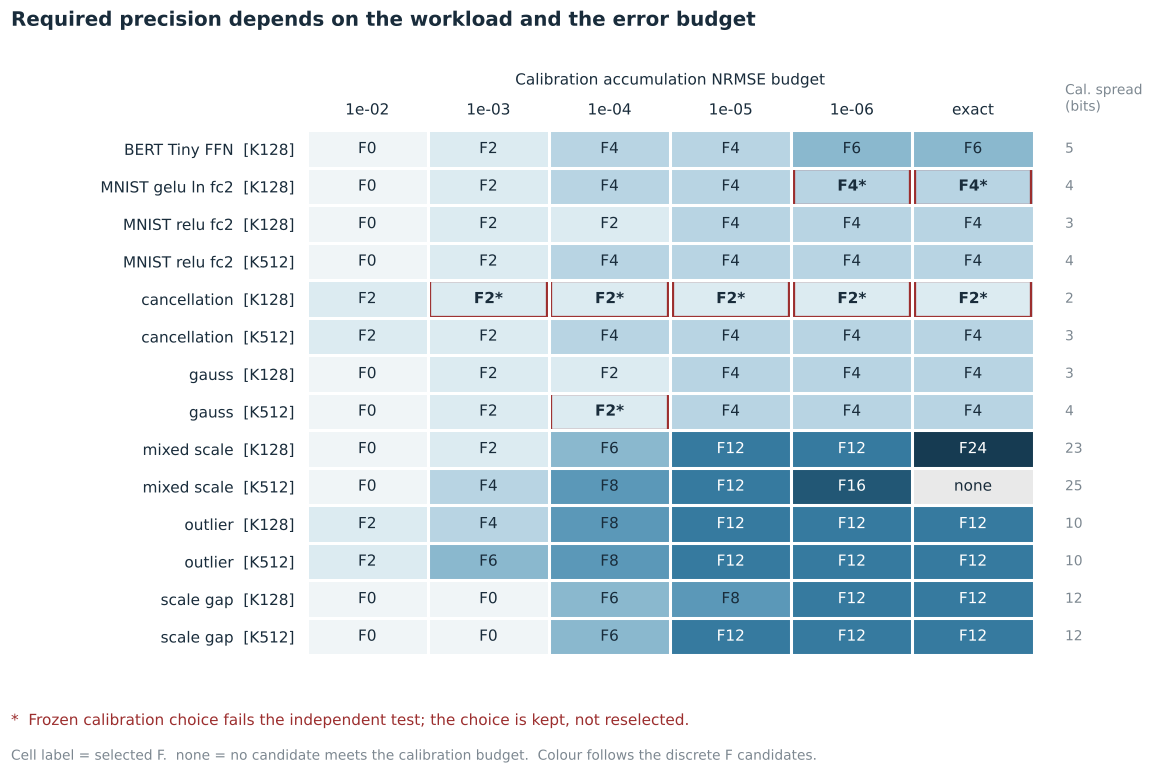

In [20]:
# 11.2 Selected F for every layer and budget (* marks a frozen choice that fails the independent test)
matrix, counts = studies.selection_matrix(PROJECT_ROOT, catalogue)
show(plots.plot_precision_matrix(matrix, studies.BUDGETS), "fig11_precision_matrix")


In [21]:
# 11.3 A real pretrained Transformer layer: BERT-Tiny encoder FFN (128 to 512) on WikiText-2 tokens
bert = studies.bert_layer(PROJECT_ROOT)


Fixed study case (independent of the panels): BERT-Tiny FFN layer, 6 budgets
google/bert_uncased_L-2_H-128_A-2, encoder.layer.0.intermediate.dense; 512 validation / 2048 test token vectors, 512 outputs
input quantization error (exact MXFP4 vs FP32, independent of F): test NRMSE 0.1191; spread cal/test 5/5 bits

  F   W  cal NRMSE  test NRMSE test max|err|
  0  16   0.002846    0.002875       0.09375
  2  18  0.0001985   0.0002077       0.01172
  4  20  2.028e-06   1.555e-06     0.0009766
  6  22          0           0             0
  8  24          0           0             0
 12  28          0           0             0
 16  32          0           0             0
 24  40          0           0             0

budget:        0.01   0.001  0.0001   1e-05   1e-06       0
selected F:      F0      F2      F4      F4      F6      F6
test pass:     True    True    True    True    True    True
fixed F4:        ok      ok      ok      ok  misses  misses

spread 5 bits: F ≥ 5 is already sufficie

## 12. Inexact Flag and Selective Exact Recompute

A low-F core can raise an *inexact* flag whenever an alignment discards a non-zero bit (flag = 0 proves the result is exact) and send only those dot products to a shared exact unit. Is that cheaper than a wider accumulator? The flag is cheap. The complete system with record storage, queue, arbiter and shared merge is not. Cells 12.1 and 12.4 use the panel configuration. Cells 12.2 and 12.3 show the implementation records.

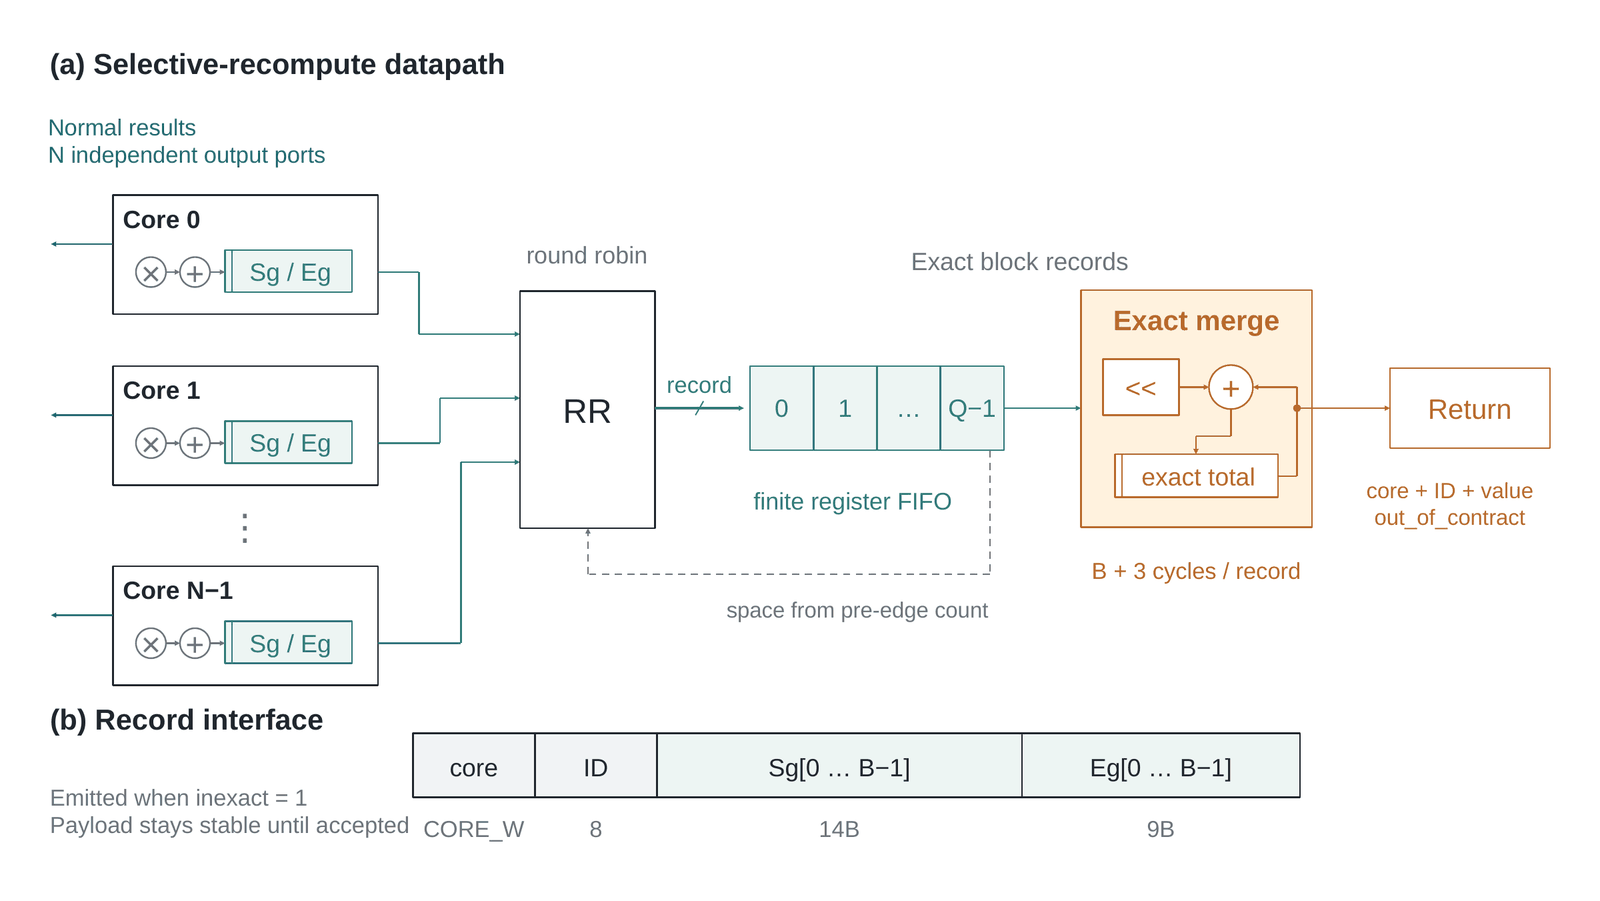

*Figure 6. The retained-record recompute system: N low-F cores keep the exact block sums of flagged dot products, a round-robin arbiter and a finite FIFO feed one shared exact merge unit, and the exact result returns tagged by core and ID.*


Configuration for Section 12 (shared with the panels of Sections 3 to 9): MNIST fc2, ReLU model (512 cal / 10,000 test, K128) [mnist_relu_fc2], K128, MXFP4 core, accumulation budget 0.1 %, total budget 12 %, clock 50 ns, at least 100,000 dot products/s
mnist_relu_fc2, test split: flagged dot products, accumulation NRMSE before and after strict exact recompute
  F   W  cal flagged  test flagged  NRMSE before  after false pos.
  0  16       41.57%        42.48%       0.00189      0      35382
  2  18     0.03662%       0.0125%      1.16e-05      0          0
  4  20           0%            0%             0      0          0
  6  22           0%            0%             0      0          0
  8  24           0%            0%             0      0          0
 12  28           0%            0%             0      0          0
 16  32           0%            0%             0      0          0
 24  40           0%            0%             0      0          0

across all 14 workloads (cached st

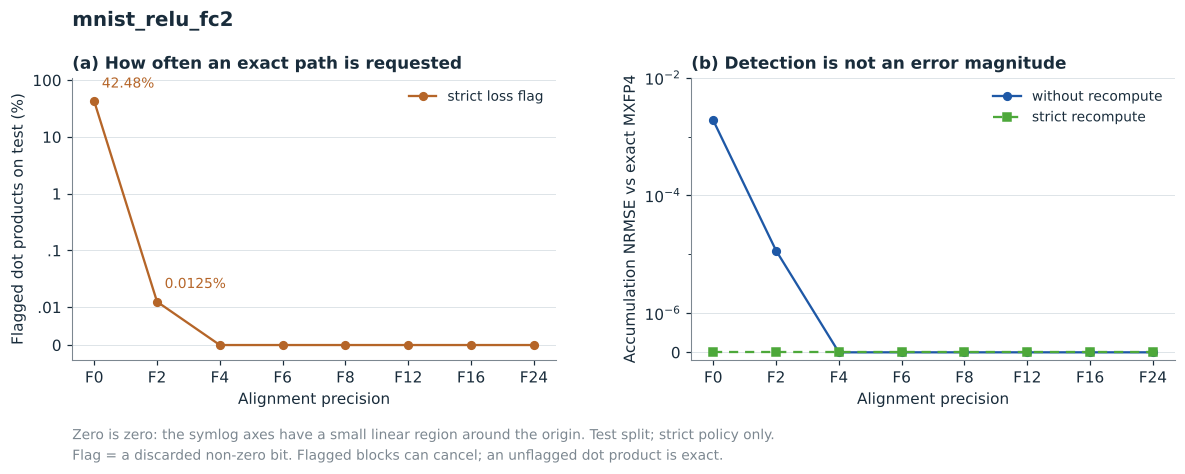

In [22]:
# 12.1 How often a low-F core discards a non-zero bit, and the error left after exact recompute (test split)
cfg = studies.panel_config(lab, section=12)
flags = studies.flag_study(PROJECT_ROOT, cfg)
show(plots.plot_recompute(flags, cfg["workload"]), "fig12a_flag_frequency")


In [23]:
# 12.2 Area of the optional flag variant: same Yosys script and same LibreLane settings as the baseline
flag_hw = studies.flag_cost(PROJECT_ROOT)


Fixed study case (independent of the panels): the MXFP4 core with and without the optional flag, K128, 50 ns (implementation records)
  F  mapped base  mapped +flag   delta    routed base  routed +flag   delta  checks
  0     41,135.9      41,840.5  +1.71%                   not routed
  2     43,146.7      43,612.0  +1.08%       58,071.8      58,317.7  +0.42%  meets every check at all corners
  4     44,384.7      45,008.2  +1.40%       62,543.4      62,604.9  +0.10%  meets every check at all corners
  6     45,330.9      45,671.1  +0.75%                   not routed
  8     46,430.7      46,922.4  +1.06%                   not routed
 12     48,737.8      48,884.9  +0.30%                   not routed
 16     50,296.4      50,891.3  +1.18%                   not routed
 24     52,889.0      53,257.7  +0.70%                   not routed


Fixed study case (independent of the panels): the recompute system as built: K128, F2 cores, 50 ns (implementation records)
component                                 mapped µm²  routed µm²  verdict
F2 core                                       43,147      58,072  
F2 + inexact flag                             43,612      58,318  
F2 + flag + record store and port             51,199      66,328  timing/DRC/LVS OK; 2 cap viol.
F4 + flag + record store and port             52,287      68,703  timing/DRC/LVS OK; 1 cap viol.
shared exact merge, D_MAX 24                  33,248      47,605  timing/DRC/LVS OK; 2 cap viol.
shared exact merge, D_MAX 12                  28,494         n/a  not routed
fixed F6 core (no recompute)                  45,331      62,774
fixed F8 core (no recompute)                  46,431      64,027
fixed F12 core (no recompute)                 48,738      61,758

full top (same die, clock and flow)       mapped µm²  routed µm²  verdict
base_n4_k128_f6               

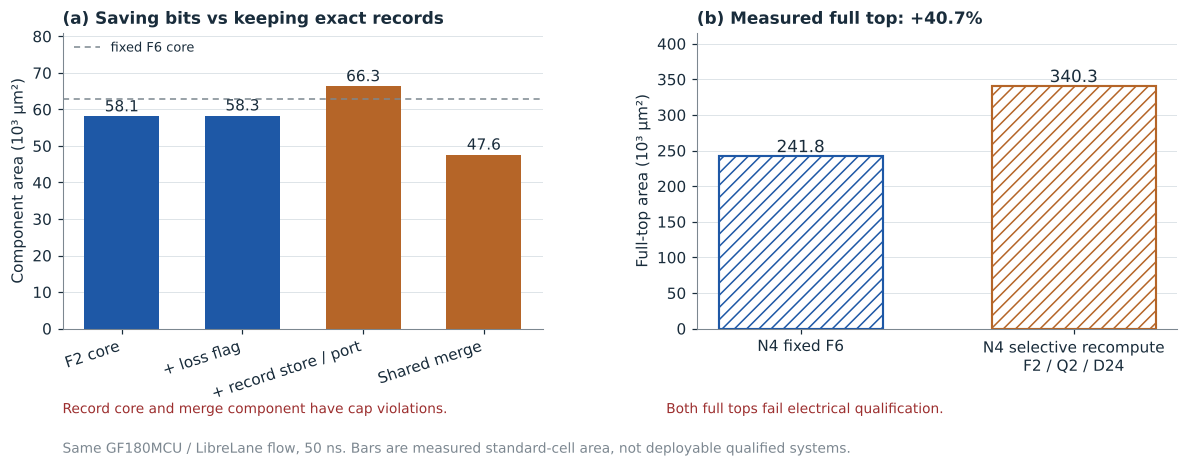

In [24]:
# 12.3 The complete recompute system, verified, synthesised and routed: components and full tops
system = studies.system_cost(PROJECT_ROOT)
show(plots.plot_system_cost(system), "fig12b_system_cost")


In [25]:
# 12.4 Strict system selection for the panel configuration: contract, budget, model scope, qualification, P99, area
system_choice = studies.system_choice(PROJECT_ROOT, cfg, MAX_P99_CYCLES, OOC_POLICY, hardware, numeric)


mnist_relu_fc2: accumulation budget 0.001, total budget 0.12, P99 ≤ 200 cycles, out-of-contract policy reject; contract checked with spread 3 (calibration split)
  rule: contract → calibration budgets (accumulation and total) → model scope (RTL-validated) → full-top qualification
        pass → throughput and P99 → smallest area per core with a consistent boundary
  single core (qualified): single_core_F2, 58,072 µm²
  strict system selection: none / not_qualified

  exploration ranking (predictions, labelled):
  candidate                 P99 burst P99  µm²/core vs single feasible  area source / qualification
  recompute_F2_N32_Q1        14        40    76,413    +31.6%      yes  component_scaled_estimate / unknown
  recompute_F2_N32_Q2        14        41    76,622    +31.9%      yes  component_scaled_estimate / unknown
  recompute_F2_N32_Q4        14        41    77,040    +32.7%      yes  component_scaled_estimate / unknown
  recompute_F2_N16_Q1        14        40    77,696    +33.

## 13. Cycle-Exact Performance Model

Fixed study case: a C++17 model of the recompute system (cores, FIFO, round-robin arbiter, shared merge) predicts timing without reading the RTL. It is checked against Icarus RTL traces on shared stimulus, cycle by cycle, and then used to study request order and queue depth.

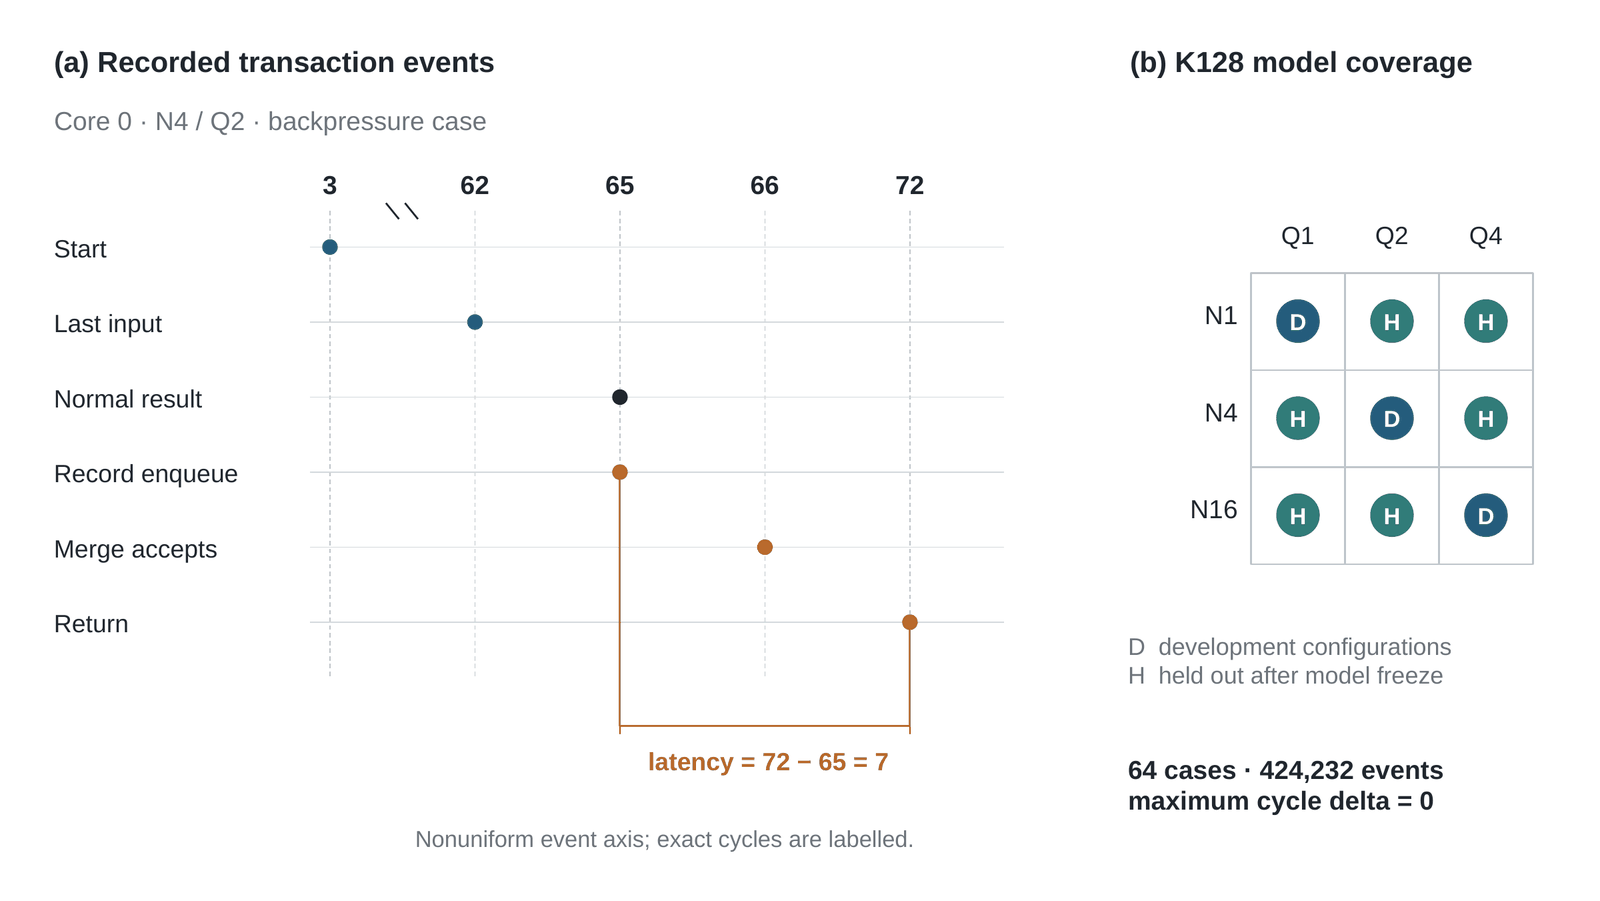

*Figure 7. Event raster of the case in cell 13.2 (four cores, queue depth 2): the first flagged record is enqueued at cycle 65, accepted by the merge unit at 66 and returned at 72. The right side shows the development and held-out configurations of the validation.*


In [26]:
# 13.1 The cycle contract and the full RTL vs C++ validation record, per configuration
validation = studies.perf_validation(PROJECT_ROOT)


Fixed study case (independent of the panels): the validation suite of the cycle model (64 recorded cases)
cycle contract 4618b27dc95342aa: no-stall II0 = 9B + 4 (40 at K128), merge service B + 3
validation record: current (every source that produced it hashes the same now)
C++ model binary 42a25d7f3001a9e2; 64/64 cases pass, 424,232 events compared, max |cycle delta| 0, comparator self-test pass

role          (N, Q) configurations cases transactions   events max|d|  traces
development                       3    25       25,234  145,794      0  identical
held_out                          6    39       47,742  278,438      0  identical
coverage in both roles: ID wrap, back-pressure, enq+deq, out of contract, queue full, reset busy


In [27]:
# 13.2 One case through the C++ model and the RTL, whose traces must agree in every cycle
live = studies.live_rtl_vs_cpp(PROJECT_ROOT, scenario="E_backpressure", n=4, q=2, tx_per_core=24)


Fixed study case (independent of the panels): validation scenario E_backpressure, 4 cores, queue depth 2, 24 transactions per core
== building the C++ performance model (cmake -S cpp -B build/perf)
case E_backpressure_n4_q2_k128_f2: 96 transactions, 46 flagged; C++ model binary 42a25d7f3001a9e2
C++: 1279 cycles, queue peak 2, P99 recompute latency 15 cycles
RTL: 1279 cycles, 0 value errors; per-cycle trace identical: True; 614 events compared, max |delta| 0

first flagged transaction (core 0):  event                        RTL   C++
                                     first_input_accept             3     3
                                     last_input_accept             62    62
                                     normal_result_handshake       65    65
                                     record_enqueue                65    65
                                     merge_accept                  66    66
                                     return_handshake              72    72


Fixed study case (independent of the panels): bert_tiny_ffn_k128 at F2, cores (4, 16), queue depths (1, 2, 4), calibration split
bert_tiny_ffn_k128 F2, calibration, up to 4096 transactions per core, saturated input (C++ model): 18 runs, 176 to 848 flagged samples per point (P99 values in the figure below)

full cached sweep, BERT F2, N16 Q2: P99 by order {'original': 23, 'shuffled': 14, 'burst': 91} cycles (384 runs)


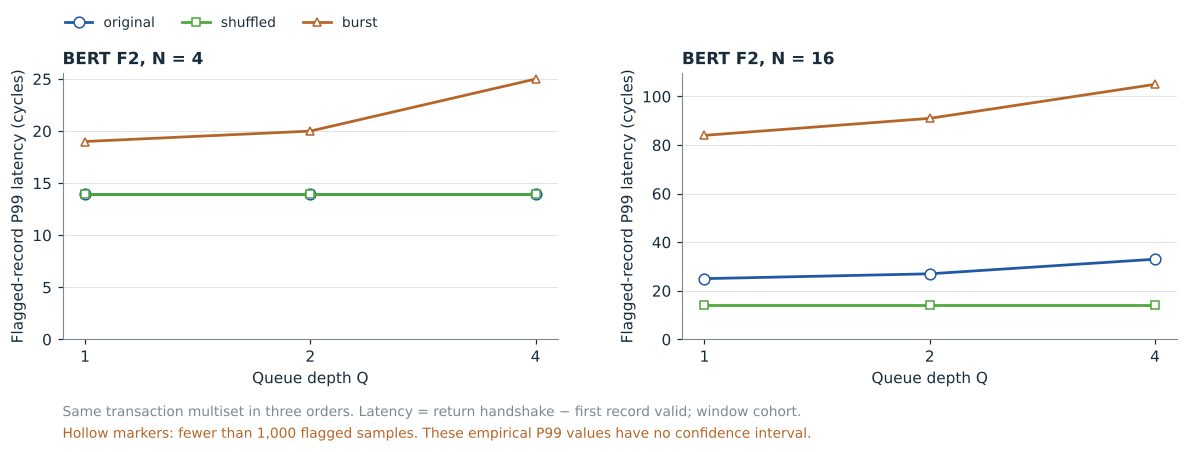

In [28]:
# 13.3 The same transactions in three issue orders: P99 recompute latency against queue depth
sweep_rows = studies.issue_order_sweep(PROJECT_ROOT, workload="bert_tiny_ffn_k128", f=2, ns=(4, 16), qs=(1, 2, 4))
show(plots.plot_live_sweep(sweep_rows, (4, 16), (1, 2, 4), "BERT F2"), "fig13_issue_order")


## 14. Conclusions

### Key Findings

**1. The accumulator width can be chosen per layer from measured evidence (F2: 7.15 % smaller than F4).**
On the MNIST layer with a 0.1 % accumulation and a 12 % total budget, F2 (W18) meets both budgets on calibration and on the independent 10,000-image test. Its routed GF180MCU core is 58,071.8 µm² against 62,543.4 µm² for F4, with +11.99 ns setup slack at 50 ns and clean DRC and LVS. F0 fails the budget. F24 meets it but has a capacitance violation, so it is excluded.

**2. Minimum bits and minimum area are different questions.**
Routed area is not monotonic in F (F12 is smaller than F4, F6 and F8), and the widest candidate fails an electrical check. The tool therefore selects among qualified routed records, never by bit count or by synthesis area alone.

**3. No single fixed width suits every layer.**
Across 14 layers and 6 budgets, a fixed F4 misses the calibration budget in 27 of 84 cases (29 on the independent test), while F0 or F2 would suffice in 32. For the BERT-Tiny FFN layer the block-exponent spread is 5 bits, so F ≥ 5 is enough for exactness. Among the scanned candidates, the first exact configuration is F6. Some frozen choices fail the independent test, and those failures stay in the result.

**4. The generic core reproduces the decision for MXFP4 inputs.**
The generic core implements the same alignment rule for six OCP MX encodings. On the MXFP4 example, W16 fails the 0.1 % budget and W18 maps to 1.82 % less area than W20, and at the same F the MXFP4 core gives identical numbers (checked by a unit test). The other encodings have mapped records but no worked decision yet.

**5. A cheap exactness certificate, but selective recompute does not pay here.**
The inexact flag never misses a lossy dot product and costs +0.42 % routed area at F2. The complete recompute system is 40.7 % larger than four fixed F6 cores, because storing exact block records costs more than the accumulator bits it saves.

**6. Timing claims rest on a validated model.**
The C++ model matches the RTL in 64 cases and 424,232 events with zero cycle error. With the same transactions, the real issue order raises the P99 recompute latency above a shuffled order (BERT F2, 16 cores, queue depth 2: 23 vs 14 cycles), so an average flag rate alone does not size the queue.

***

### Significance

This is an open, executable path from a layer's error budget to a signed-off accumulator: bit-exact numerics, generated RTL with regressions, and routed GF180MCU records, joined by RTL hash so that no number is reused across designs. It never shows a number it has not measured, and it reports the cases where the right answer is "no eligible candidate". Related work trains or constrains weights to avoid accumulator overflow (A2Q, AXE), infers widths for supported model graphs (hls4ml), or proposes new MX datapaths (Precision-Scalable MX, VMXDOTP). This notebook does not claim a new datapath. It makes the width decision of one MX core auditable on one open flow, and the flow works for any layer a designer exports.

***

### Future Work

- Layout, timing closure and power for the generic MX core, whose evidence stops at technology mapping today.
- Worked decisions for the other five MX encodings of the generic core.
- Activity-based power from simulation traces. The routed records carry only a vectorless flow estimate.
- Several place-and-route seeds per candidate, to separate placement noise from a precision effect.
- Pipelining or more lanes for clocks below 50 ns. At 35 ns the limit is the multiply and add path, which does not depend on F.
- Electrically clean N-core system tops, so that a system selection can qualify.

***

### Tools Used (All Open Source)

| Tool | Version | Purpose |
|:-|:-|:-|
| Python, NumPy, Matplotlib, ipywidgets | Python 3.10 or newer | bit-exact numerics, figures, interactive panels |
| Icarus Verilog | 13.0 (devel) | RTL regressions, RTL traces for the C++ comparison |
| Yosys and ABC | 0.62 | technology mapping, RTL and gate-level circuit views |
| LibreLane (OpenROAD, Magic, Netgen, KLayout) | 3.0.16 | place and route, nine-corner STA, DRC, LVS |
| GF180MCU PDK, gf180mcu_fd_sc_mcu7t5v0 | revision 54435919 | technology and standard cells |
| Graphviz | 2.43 | circuit drawings |
| C++17 compiler and CMake | g++ 13 | cycle-exact performance model |
| Google Colab | | reproducible cloud execution |

### Reproducibility

Click **Runtime → Run all** (after the first-run setup in Section 1). All tools are open-source. The GF180MCU PDK is publicly available. Apache 2.0 licensed.

The repository folder `ISSCC27/submitted_notebooks/mx_precision_lab/` (branch `submit-mx-precision-lab` of `12yuuuu/sscs-ose-code-a-chip.github.io`, and `main` of `sscs-ose/sscs-ose-code-a-chip.github.io` after the merge) holds three files: `README.md`, `submission.ipynb` and `mx_precision_lab_support.zip` (18 MB, SHA-256 `9abc7dd1c371d331`). Section 1 uses the ZIP next to the notebook, or downloads it from GitHub, and unpacks it into the folder `mx_precision_lab_support/`. It holds the code, RTL, C++ model, flow configuration, records, evidence views and layer data. `SUPPORT.json` lists what is in the package, what is rebuilt and what is only recorded, and `SHA256SUMS` holds the hash of every file. All paths below are inside `mx_precision_lab_support/`.

- **Routed records.** `scripts/run_flow.py` reproduces them in the pinned LibreLane environment of `flow/environment.json`. The raw signoff reports of F2 and F4 are in `results/physical/f2/evidence/` and `results/physical/f4/evidence/`. The rest of what those runs produced (226 MB) is the historical record, referenced by SHA-256 only.
- **Your own layer.** Export `calibration.npz` and `test.npz` with keys `x` (rows × K) and `w` (outputs × K, the same in both files). Then choose *Your own layer export* in Section 3. `src/mxlab/torch_bridge.py` exports every `torch.nn.Linear` of a PyTorch model with forward hooks.
- **Concept figures.** The editable artwork of Figures 3 and 4 is `assets/concept_mxfp4_core.svg` and `assets/concept_generic_core.svg`. `scripts/draw_core_concepts.py` rebuilds their PNG, SVG and PDF files.
- **Submission bundle.** Section 15 writes `results/submission_bundle.zip`, including the SVG figures and their drawing script.

Run locally:

```bash
python -m pip install numpy matplotlib ipywidgets jupyterlab
jupyter lab submission.ipynb
```


## 15. Submission Bundle

Pack the figures of this run, the selected core's RTL and layout views, and the decision records into one ZIP, with a README of the key results and the SHA-256 of every file. Before the ZIP is written, every evidence check runs again. If one fails, any earlier bundle is deleted and no new one is written. In Colab, download the ZIP from the Files panel.


In [29]:
# 15.1 Build the bundle: figures, diagrams, RTL, layout views and records, with a README
from mxlab.bundle import build as build_bundle, summary
bundle_path = build_bundle(PROJECT_ROOT, lab=lab, hardware=hardware)


evidence checks passed before this bundle was written: all 1106 support files, the raw signoff reports of F2 and F4, the provenance of 15 implementation records and the cycle-model validation record
contents: 10 diagrams, 8 figures, 3 layout, 1 readme, 12 records, 3 rtl (the README inside lists every file with its SHA-256)
bundle: results/submission_bundle.zip (2.9 MB, 37 files)


In [30]:
# 15.2 Final summary of this run
key_results = summary(PROJECT_ROOT, lab=lab, hardware=hardware)


  MX Precision Lab · IEEE SSCS Code-a-Chip · ISSCC 2027
  Configuration (panels)     mnist_relu_fc2, accumulation ≤ 0.1 %, total ≤ 12 %, 50 ns
  Selected core              MXFP4 W18 (F2), K128, P4
  Routed area (GF180MCU)     58,071.8 µm²
  Timing at 50 ns            setup +11.99 ns, hold +0.21 ns, 9 STA corners
  Signoff                    Magic DRC 0, Netgen LVS 0
  Case A (fixed, 0.1 %/12 %) W18 (F2) 7.15 % below W20 (F4), routed
  Generic MX core (MXFP4)    W18 maps to 1.82 % less area than W20
  Workload study             fixed F4 misses 27 of 84 cases; F0/F2 suffice in 32
  RTL regression             16,165 + 1,362 transactions, 0 mismatches
  Inexact flag (routed)      +0.42 % at F2, +0.10 % at F4
  Selective recompute top    +40.7 % area vs fixed F6: rejected
  C++ model vs RTL           64 cases, 424,232 events, max error 0 cycles
  License: Apache 2.0 · Tools: open source · PDK: GF180MCU (public)
